# Шлиссельбург: кварталы, застройка и доступность школ

Цель работы состоит в том, чтобы по данным OpenStreetMap выделить кварталы Шлиссельбурга, охарактеризовать функции территории и параметры застройки, оценить численность населения и доступность школьных мест. Кварталы строятся по улицам, железным дорогам и воде, как в примере BlocksNet. Здания и сведения об использовании территории получены из OpenStreetMap. Положение существующих школьных корпусов взято из геоданных предыдущей учебной работы «Моделирование территории». Вместимость учебных корпусов принята по сведениям, опубликованным на сайтах образовательных организаций. Рассмотрены два режима передвижения, пешком и на автомобиле, с одинаковыми кварталами, населением и школьными местами.

Работа выполнена с помощью **BlocksNet 1.0.0a9**, библиотеки Python для анализа городской территории. Назначение части зданий в OSM не уточнено. Дата состояния сведений о вместимости школьных корпусов не установлена. Это ограничивает точность оценки населения и выводов об обеспеченности школьными местами.

| Группа показателей | Необходимые данные | Результаты и единицы |
| --- | --- | --- |
| Использование территории по OSM | Границы кварталов и зоны использования из OSM | Доли семи функций, 0..1; преобладающая функция и её доля |
| Время в пути | Уличная сеть выбранного режима, скорости и точки кварталов | Матрица времени между кварталами, мин |
| Здания и население | Контуры зданий, назначение и этажность | Число зданий, площади в м², этажность и оценка жителей в чел. |
| Школы | Положение корпусов из предыдущей учебной работы; вместимость по сведениям сайтов образовательных организаций | Число корпусов, вместимость в местах |
| Обеспеченность школами | Население, вместимость, матрица времени и параметры потребности в местах | Два показателя обеспеченности, 0..1; расчётная потребность, остатки и распределённые места |
| Плотность | Площадь квартала, пятно, поэтажная, жилая и прочая площади | FSI, GSI, MXI, L, OSR и отношения площадей; определения и единицы приведены в разделе 6 |
| Типы застройки | L, FSI и MXI | Типы Spacematrix и Стрелки; характеристики групп Spacematrix |
| Доступность с учётом площади | Матрица времени и площади кварталов | Среднее время до всех кварталов, мин |

### План работы

1. Проверить границу Шлиссельбурга и выбрать метрическую систему координат.
2. Подготовить исходные слои OSM и существующие школьные корпуса, сохранить данные и сведения об источниках.
3. Построить кварталы по улицам, железным дорогам и воде, проверить геометрию и использование территории.
4. Разобрать смысл показателей BlocksNet, их единицы и необходимые данные перед расчётами.
5. Рассчитать характеристики зданий, население, плотность и типы застройки; получить время между кварталами для пешего и автомобильного режимов.
6. Рассчитать распределение школьных мест и среднее время до всех кварталов, сохранить результаты в GeoJSON и проверить повторное чтение.
7. Сопоставить кварталы и способы передвижения, сформулировать выводы и собрать интерактивный дашборд из сохранённых результатов.

### Основные запросы к исследованию

- Подготовить данные и кварталы Шлиссельбурга по примеру BlocksNet, предусмотрев сохранение и повторное использование файлов.
- Перечислить все показатели из `pipeline.ipynb`, объяснить их смысл, единицы измерения и необходимые исходные данные.
- Выполнить расчёты для пешего и автомобильного передвижения; показать модельные допущения, отсутствие данных и ограничения результатов.
- Создать отдельный Python-файл для сборки `dashboard.html` из готовых результатов: интерактивная карта, графики, таблицы всех показателей и краткие выводы.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import enum
import hashlib
import importlib.metadata
import json
import math
import sys
import time
import warnings
import textwrap

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Point, LineString, Polygon, MultiPolygon, mapping
from shapely.ops import unary_union
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import folium
import networkx as nx
import osmnx as ox
from IPython.display import display, HTML, Markdown
from loguru import logger

def show_library_message(record):
    message=record['message']
    expected={
        'Creating empty railways','Creating empty buildings','Matrix contains inf values',
        'No demand in columns. Imputing using population column and demand parameter'
    }
    return message not in expected and not (message.startswith('Column ') and message.endswith('not found and will be initialized as None'))

def configure_notebook_logging():
    logger.configure(handlers=[{'sink':sys.stderr,'level':'WARNING','colorize':False,'format':'{level.name}: {message}','filter':show_library_message}])

configure_notebook_logging()
warnings.filterwarnings('ignore',message=r'`torch\.jit\.script` is deprecated.*',category=FutureWarning)

def morphotype_title(value):
    if value is None or pd.isna(value):
        return 'Не классифицировано'
    special={
        'individual residential':'Модель индивидуальной застройки',
        'low-rise model':'Малоэтажная модель',
        'mid-rise':'Среднеэтажная модель',
        'mid-rise microdistrict':'Среднеэтажный микрорайон',
        'mid-rise block':'Среднеэтажная квартальная модель',
        'central model':'Модель центральной застройки',
        'high-rise soviet microdistrict':'Многоэтажный микрорайон советской модели',
        'high-rise modern microdistrict':'Многоэтажный микрорайон современной модели'
    }
    text=str(value)
    if text in special: return special[text]
    pieces=[]
    for token,label in [('high-mid-rise','Повышенная средняя этажность'),('low-rise','Малоэтажная'),('mid-rise','Среднеэтажная'),('high-rise','Многоэтажная'),('tower','Башенная')]:
        if text.startswith(token): pieces.append(label); break
    if 'low-density' in text: pieces.append('низкая плотность')
    if 'high-density' in text: pieces.append('высокая плотность')
    if 'non-residential' in text: pieces.append('малая расчётная доля жилья')
    elif 'mixed-use' in text: pieces.append('смешанный тип')
    elif 'residential' in text: pieces.append('преимущественно жилой тип')
    return ', '.join(pieces) if pieces else text

def number_text(value,digits=0):
    if value is None or not np.isfinite(value): return 'нет конечного значения'
    if round(float(value),digits)==0: value=0
    return f'{value:,.{digits}f}'.replace(',','\u00a0').replace('.',',')

def count_text(value,one,few,many):
    n=abs(int(value))
    form=many if 11<=n%100<=14 else one if n%10==1 else few if 2<=n%10<=4 else many
    return number_text(value)+' '+form

MODE_LABELS = {'walk':'Пешком', 'drive':'На автомобиле'}
TABLE_LABELS = {
    'osm_type':'Тип объекта OSM', 'osm_id':'Идентификатор OSM', 'display_name':'Название территории',
    'node':'Узлов node', 'way':'Объектов way', 'relation':'Составных объектов relation',
    'residential':'Доля жилой функции', 'business':'Доля деловой функции',
    'recreation':'Доля рекреационной функции', 'industrial':'Доля промышленной функции',
    'transport':'Доля транспортной функции', 'special':'Доля специальной функции',
    'agriculture':'Доля сельскохозяйственной функции', 'land_use':'Преобладающая функция',
    'share':'Доля преобладающей функции', 'site_area':'Площадь квартала, м²',
    'building_tag':'Тип здания по OSM', 'building_count':'Объектов зданий',
    'is_living':'Жилых объектов', 'number_of_floors':'Сумма этажностей',
    'floors_estimated':'Этажность принята по допущению',
    'footprint_area':'Пятно зданий, м²', 'build_floor_area':'Поэтажная площадь, м²',
    'living_area':'Расчётная жилая площадь, м²', 'non_living_area':'Прочая расчётная площадь, м²',
    'population':'Модельное население, чел.', 'name':'Название', 'osm_key':'Идентификатор OSM',
    'school_count':'Учебных корпусов', 'capacity':'Вместимость, мест',
    'capacity_source_label':'Источник вместимости',
    'fsi':'FSI, м²/м²', 'gsi':'GSI, доля', 'mxi':'MXI, доля', 'l':'L, этажей', 'osr':'OSR, м²/м²',
    'share_living':'Жилая площадь к пятну, м²/м²',
    'share_non_living':'Прочая расчётная площадь к пятну, м²/м²',
    'spacematrix_cluster':'Кластер Spacematrix', 'spacematrix_morphotype':'Тип Spacematrix',
    'strelka_morphotype':'Тип Стрелки',
    'demand':'Потребность в местах', 'demand_left':'Необеспечённая потребность в местах',
    'demand_within':'Выделено жителям в пределах порога, мест',
    'demand_without':'Выделено жителям за пределами порога, мест',
    'capacity_left':'Свободные места после распределения',
    'capacity_within':'Выделено другим кварталам в пределах порога, мест',
    'capacity_without':'Выделено другим кварталам за пределами порога, мест',
    'provision_strong':'Обеспеченность в пределах порога, доля',
    'provision_weak':'Обеспеченность с учётом дальних поездок, доля',
    'provision_strong_weighted':'Покрытая доля потребности, 0..1',
    'reachable_pairs':'Пар кварталов с путём, включая диагональ', 'total_pairs':'Всего пар кварталов',
    'area_accessibility_unreachable':'Кварталов без конечного среднего времени'
}

def display_table(frame, labels=None, index_label=None):
    view = frame.rename(columns={**TABLE_LABELS, **(labels or {})})
    if index_label is not None:
        view = view.rename_axis(index_label)
    display(view)

def accessibility_text(value, status):
    if isinstance(status, str) and status == 'unreachable':
        return '∞'
    if value is None or pd.isna(value) or not np.isfinite(value):
        return 'нет данных'
    return number_text(value, 2)

PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
STUDY = PROJECT / 'examples' / 'shlisselburg'
MAP_STYLE = json.loads((STUDY / 'map_style.json').read_text(encoding='utf-8'))
MAP_NUMERIC_CMAP = LinearSegmentedColormap.from_list('shlisselburg_numeric', MAP_STYLE['numeric'])
MAP_NUMERIC_CMAP.set_bad(MAP_STYLE['missing'])
MAP_CATEGORIES = {field: list(colors) for field, colors in MAP_STYLE['categories'].items()}
MAP_CATEGORY_CMAPS = {
    field: ListedColormap(list(colors.values()), name='shlisselburg_' + field)
    for field, colors in MAP_STYLE['categories'].items()
}
for category_cmap in MAP_CATEGORY_CMAPS.values():
    category_cmap.set_bad(MAP_STYLE['missing'])

def plot_water_background(ax):
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    ax.set_facecolor(MAP_STYLE['mapBackground'])
    ax.add_patch(plt.Rectangle((0,0),1,1,transform=ax.transAxes,facecolor=MAP_STYLE['mapBackground'],edgecolor='none',zorder=-1,clip_on=False))
    if len(water_polygons):
        water_polygons.plot(ax=ax, color=MAP_STYLE['water'], zorder=0)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

RAW = STUDY / 'data' / 'raw'
PREPARED = STUDY / 'data' / 'prepared'
RESULTS = STUDY / 'results'
GRAPHS = RESULTS / 'graphs'
MATRICES = RESULTS / 'matrices'
CACHE = STUDY / 'data' / 'cache'
for folder in (RAW, PREPARED, RESULTS, GRAPHS, MATRICES, CACHE):
    folder.mkdir(parents=True, exist_ok=True)

REFRESH_DATA = False
REFRESH_BARRIER_DATA = False
CITY_QUERY = 'Шлиссельбург, Кировский район, Ленинградская область, Россия'
WALK_SPEED_KPH = 5.0
LIVING_AREA_PER_PERSON = 30.0
RANDOM_STATE = 42
ox.settings.use_cache = True
ox.settings.cache_folder = str(CACHE)
ox.settings.requests_timeout = 180
ox.settings.http_user_agent = 'ShlisselburgCourseStudy/1.0 (local educational research)'
ox.settings.http_accept_language = 'ru'
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 130

def clean_value(value):
    if value is None or value is pd.NA:
        return None
    if isinstance(value, enum.Enum):
        return value.value
    if isinstance(value, dict):
        return {str(k): clean_value(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set, np.ndarray)):
        return [clean_value(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(float(value)) else None
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, (str, int)):
        return value
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass
    return str(value)

def save_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(clean_value(obj), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def save_geojson(frame, path, keep_index=False):
    frame = frame.copy()
    if frame.crs is None:
        raise ValueError('У геоданных не задана система координат.')
    if keep_index and 'block_id' not in frame:
        frame['block_id'] = frame.index.astype(int)
    for column in frame.columns.drop('geometry'):
        if frame[column].dtype == object:
            frame[column] = frame[column].map(clean_value)
    frame = frame.to_crs(4326)
    payload = json.loads(frame.to_json(drop_id=True, na='null'))
    save_json(path, payload)

manifest_path = RESULTS / 'manifest.json'
manifest = json.loads(manifest_path.read_text(encoding='utf-8')) if manifest_path.exists() else {}
manifest.update({
    'title': 'Шлиссельбург: кварталы и доступность',
    'city': CITY_QUERY,
    'captured_at': manifest.get('captured_at'),
    'captured_at_scope': 'osm_xml_snapshot',
    'source': 'OpenStreetMap contributors, ODbL; положение школьных корпусов: геоданные предыдущей учебной работы; вместимость: сведения сайтов образовательных организаций',
    'versions': {p: importlib.metadata.version(p) for p in ['blocksnet','iduedu','osmnx','geopandas','networkx','numpy','pandas']},
    'assumptions': [
        'Пешеходная скорость 5 км/ч принята как постоянная модельная скорость.',
        'Автомобильные скорости определяются по типам дорог по конфигурации IduEdu; пробки и поиск парковки не моделируются.',
        'При отсутствии населения жилых зданий используется 30 м² жилой площади на человека, как в учебном примере.',
        'Жилое назначение принимается только по явным типам building из учебного примера; building=yes не считается подтверждением жилья. В allotments постоянное население не назначается.',
        'Вместимости двух существующих школьных корпусов, 683 и 934 места, приняты по сведениям, опубликованным на сайтах образовательных организаций.',
        'Параметры потребности в школьных местах и времени из настройки school применяются как учебные расчётные параметры. Один порог отдельно используется для пешеходной и автомобильной матриц; автомобильные 15 минут не являются проверенным нормативом.'
    ],
    'limitations': [
        'Полнота и актуальность OpenStreetMap зависят от наполнения базы.',
        'Дата получения ранее сохранённых отдельных слоёв OSM не зафиксирована; дата XML-выборки относится только к ней.',
        'Дата состояния сведений о вместимости, опубликованных на сайтах образовательных организаций, не установлена; значения используются как предоставленные входные данные.',
        'Неуточнённое назначение building=yes влияет на население, жилую и прочую площадь, MXI и обе типологии. Низкая расчётная доля жилья не подтверждает фактическую нежилую функцию.',
        'Оценки площадей и населения зависят от полноты контуров и этажности.',
        'Кварталы построены по картографическим барьерам и не являются официальными кадастровыми кварталами.',
        'Водный и общественный транспорт не моделируются.',
        'Расчёт между представительными точками кварталов является приближением доступности, а не маршрутом от конкретной двери до школы.'
    ]
})
manifest.setdefault('input_sources', {})

def remember_source(name, source, file, from_saved, obtained_at=None):
    entry=manifest['input_sources'].setdefault(name, {})
    if not from_saved:
        entry['obtained_at']=obtained_at or datetime.now(ZoneInfo('Europe/Moscow')).isoformat()
    entry.setdefault('obtained_at', None)
    entry.update(source=source, file=str(file), date_status='recorded' if entry['obtained_at'] else 'not_recorded')
    return entry

manifest['stages'] = {}

def stage(name, **details):
    manifest['stages'][name] = {'updated_at': datetime.now(ZoneInfo('Europe/Moscow')).isoformat(), **clean_value(details)}
    save_json(manifest_path, manifest)

assert manifest['versions']['blocksnet'] == '1.0.0a9'
display(pd.DataFrame([{'Компонент': k, 'Версия': v} for k, v in manifest['versions'].items()]))
print('Рабочая папка:', STUDY.relative_to(PROJECT).as_posix())
print('Повторная загрузка исходников:', REFRESH_DATA)

,Компонент,Версия
0,blocksnet,1.0.0a9
1,iduedu,0.4.1
2,osmnx,2.1.1
3,geopandas,1.2.0
4,networkx,3.7
5,numpy,2.2.6
6,pandas,2.3.3


Рабочая папка: examples/shlisselburg
Повторная загрузка исходников: False


## 1. Территория исследования

В OSM сохранены два разных контура: населённый пункт Шлиссельбург и Шлиссельбургское городское поселение. В работе использована **муниципальная граница**, которая включает водную часть и острова. Муниципальная граница охватывает городскую застройку и Ореховый остров с крепостью Орешек. Контур населённого пункта показан отдельно для ориентации.

Площадь муниципального полигона включает воду. Площадь кварталов получается после исключения водных полигонов; это другая величина. Контуры из OSM служат пространственной основой учебной модели. Их название и положение сопоставлены с [описанием муниципальной территории](https://mo-shlisselburg.ru/about/granici).

Исходная карта использует широту и долготу. Для вычисления площадей и расстояний геометрия переведена в метрическую систему **UTM 36N, EPSG:32636**. Система координат задаёт способ измерения положения объектов; здесь единицей длины служит метр. Файлы для браузерной карты сохранены обратно в широте и долготе, EPSG:4326. Поэтому площади рассчитаны по метрической геометрии, а не по угловым координатам.

Область модели: муниципальная граница Шлиссельбургского городского поселения.


,Тип объекта OSM,Идентификатор OSM,Название территории
0,relation,1767167,"Шлиссельбургское городское поселение, Кировски..."


Площадь выбранной границы, включая воду: 44.879 км². Метрическая проекция: EPSG:32636.


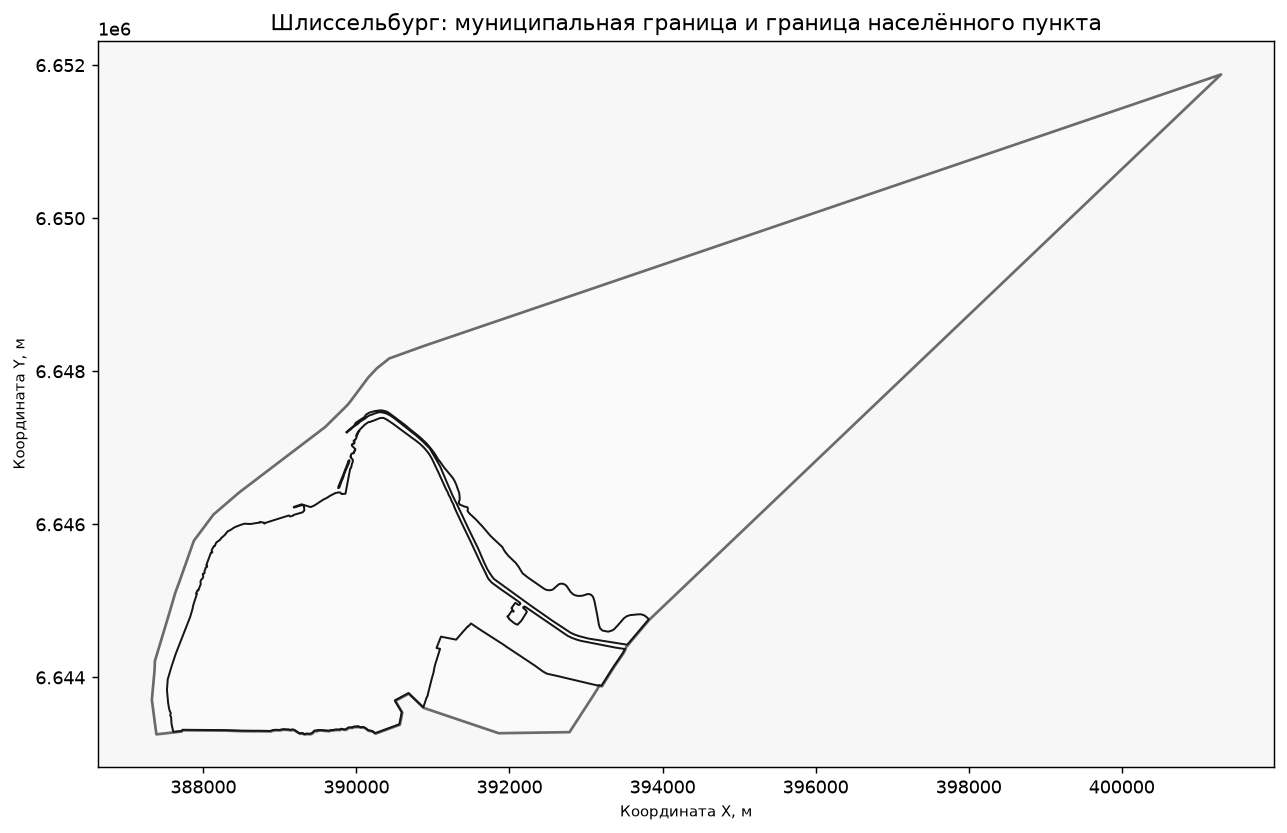

In [2]:
locality_file = RAW / 'boundary_locality.geojson'
municipality_file = RAW / 'boundary_municipality.geojson'
boundary_file = RAW / 'boundary.geojson'
if locality_file.exists() and not REFRESH_DATA:
    locality = gpd.read_file(locality_file)
    locality_from_saved = True
elif boundary_file.exists() and not REFRESH_DATA:
    previous_boundary = gpd.read_file(boundary_file)
    if int(previous_boundary.iloc[0].get('osm_id', 0)) == 1430462:
        locality = previous_boundary
        locality_from_saved = True
    else:
        locality = ox.geocode_to_gdf(CITY_QUERY)
        locality_from_saved = False
    save_geojson(locality, locality_file)
else:
    locality = ox.geocode_to_gdf(CITY_QUERY)
    locality_from_saved = False
    save_geojson(locality, locality_file)
if municipality_file.exists() and not REFRESH_DATA:
    municipality = gpd.read_file(municipality_file)
    municipality_from_saved = True
else:
    municipality = ox.geocode_to_gdf('Шлиссельбургское городское поселение, Кировский район, Ленинградская область, Россия')
    save_geojson(municipality, municipality_file)
    municipality_from_saved = False
remember_source('boundary_locality','OpenStreetMap via Nominatim','data/raw/boundary_locality.geojson',locality_from_saved)
remember_source('boundary_municipality','OpenStreetMap via Nominatim','data/raw/boundary_municipality.geojson',municipality_from_saved)
boundary = municipality.copy()
save_geojson(boundary, boundary_file)
print('Область модели: муниципальная граница Шлиссельбургского городского поселения.')

assert len(boundary) == 1, 'Ожидается один выбранный объект границы.'
assert boundary.geometry.geom_type.isin(['Polygon', 'MultiPolygon']).all()
assert boundary.geometry.is_valid.all(), 'Требуется проверить невалидную геометрию границы.'
assert not boundary.geometry.is_empty.any()
CRS = boundary.estimate_utm_crs()
assert CRS is not None
boundary_m = boundary.to_crs(CRS)
AREA_KM2 = float(boundary_m.geometry.area.sum() / 1_000_000)
boundary_geometry = boundary.to_crs(4326).geometry.union_all()
manifest['crs'] = str(CRS)
stage('boundary', status='saved', area_km2=AREA_KM2,
      osm_type=boundary.iloc[0].get('osm_type'), osm_id=boundary.iloc[0].get('osm_id'),
      display_name=boundary.iloc[0].get('display_name'), bounds=list(boundary_geometry.bounds))
manifest['boundary_scope'] = 'Муниципальная граница Шлиссельбургского городского поселения, включая воду; сухопутные кварталы выделяются отдельно.'
manifest['boundary_locality'] = {'osm_id': int(locality.iloc[0]['osm_id']), 'area_km2': float(locality.to_crs(CRS).area.sum()/1_000_000)}
save_json(manifest_path, manifest)
display_table(boundary[['osm_type','osm_id','display_name']])
print(f'Площадь выбранной границы, включая воду: {AREA_KM2:.3f} км². Метрическая проекция: {CRS}.')

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_facecolor(MAP_STYLE['mapBackground'])
boundary_m.plot(ax=ax, facecolor=MAP_STYLE['land'], edgecolor=MAP_STYLE['boundary'], linewidth=1.5)
locality.to_crs(CRS).boundary.plot(ax=ax, color=MAP_STYLE['selection'], linewidth=1.1)
ax.set_title('Шлиссельбург: муниципальная граница и граница населённого пункта')
ax.set_xlabel('Координата X, м')
ax.set_ylabel('Координата Y, м')
ax.set_aspect('equal')
fig.tight_layout()
fig.savefig(RESULTS / 'boundary.png', dpi=170, bbox_inches='tight')
plt.show()

center = boundary_geometry.representative_point()
boundary_map = folium.Map(location=[center.y, center.x], zoom_start=13, tiles=None)
folium.GeoJson(boundary.to_crs(4326).__geo_interface__, name='Муниципальная граница',
    style_function=lambda f: {'color':MAP_STYLE['boundary'],'fillColor':MAP_STYLE['land'],'weight':3,'fillOpacity':0.08}).add_to(boundary_map)
folium.GeoJson(locality.to_crs(4326).__geo_interface__, name='Населённый пункт',
    style_function=lambda f: {'color':MAP_STYLE['selection'],'weight':2,'fillOpacity':0}).add_to(boundary_map)
boundary_map.get_root().header.add_child(folium.Element(
    '<style>.folium-map {background:' + MAP_STYLE['mapBackground'] + ';}</style>'))
folium.LayerControl().add_to(boundary_map)
boundary_map.get_root().html.add_child(folium.Element('<div style="position:fixed;bottom:2px;left:4px;background:white;padding:2px 6px;z-index:9999;font-size:11px">Границы: © <a href="https://www.openstreetmap.org/copyright">OpenStreetMap contributors</a></div>'))
boundary_map.fit_bounds([[boundary_geometry.bounds[1], boundary_geometry.bounds[0]],
                        [boundary_geometry.bounds[3], boundary_geometry.bounds[2]]])
display(boundary_map)

## 2. Исходные данные

OpenStreetMap, сокращённо OSM, хранит геометрию объектов и их **теги**: пары названия свойства и значения. Например, `building=apartments` обозначает многоквартирный жилой дом. Полнота этих свойств зависит от наполнения карты. В работе из OSM получены улицы, железные дороги, вода, сведения об использовании территории и здания. Положение двух существующих школьных корпусов взято из геоданных учебной работы «Моделирование территории». Вместимость учебных корпусов принята по сведениям, опубликованным на сайтах образовательных организаций.

| Слой | Источник | Использование в работе |
| --- | --- | --- |
| Дороги | OSM | Линии разделения кварталов; для транспортных сетей отдельно отбираются разрешённые пути каждого режима |
| Железные дороги | OSM | Дополнительные линии разделения территории, если такие объекты есть внутри выбранной границы |
| Вода | OSM | Линии водотоков и водные полигоны; водные площади исключены из кварталов, подходы к сети проверены на пересечение воды |
| Использование территории по OSM, `landuse` | OSM | Размеченные виды использования территории для расчёта долей функций |
| Здания | OSM | Контуры, известный тип здания и этажность; основа расчётных площадей и оценки населения |
| Учебные корпуса школы | Геоданные предыдущей учебной работы; вместимость по сведениям сайтов образовательных организаций | Две геометрии и переданные вместимости: 683 и 934 места |

Слой `landuse` описывает сведения карты об использовании территории и отличается по назначению от нормативного зонирования ПЗЗ.

Каждый слой сохранён в **GeoJSON**. Это текстовый формат, в котором рядом хранятся геометрия объекта и его свойства. Слой существующих школьных корпусов находится в `data/prepared/manual_schools_primary.geojson`; его происхождение и контрольная сумма указаны в соседнем `manual_schools_source.json`. Это локальная копия файла `Геоданные/Сервисы/school.geojson` из предыдущей учебной работы. Повторный запуск читает эту копию. Сведения о вместимости получены с сайтов образовательных организаций; дата состояния этих сведений не установлена.

Для ранее сохранённых отдельных слоёв границ, дорог, железных дорог, воды, использования территории и зданий дата получения не зафиксирована. Интервал получения общей XML-выборки указан отдельно в `osm_snapshot.json` и относится только к этой выборке. Даты не восстанавливаются по времени изменения файлов. При новой загрузке дата записывается в `manifest.json`, а чтение сохранённых данных её не заменяет.

В таблице ниже приведено число прочитанных объектов, источник и известная дата получения каждого слоя. Ноль в слое OSM означает пустую полученную выборку; ошибка обращения к источнику останавливает соответствующую загрузку и не записывается как отсутствие объектов.

### Как сохранена исходная карта

Здания и сети двух режимов получены из общей локальной выборки OSM. Она охватывает муниципальную территорию и пояс 2 км вокруг неё. Дополнительный пояс нужен, чтобы пути между городскими кварталами могли проходить за муниципальной границей. Водные объекты и сведения об использовании территории по OSM сохранены отдельными полными слоями.

Файл `data/raw/osm_snapshot.osm` содержит исходные объекты и теги в формате XML. Идентификаторы объектов позволяют сопоставлять одни и те же здания и корпуса в разных наборах. Рядом сохранён `osm_snapshot.json` с датами получения, адресами запросов и контрольной суммой файла. Контрольная сумма позволяет проверить, что использована та же выборка.

Данные получены через [Map API OpenStreetMap](https://wiki.openstreetmap.org/wiki/API_v0.6#Retrieving_map_data_by_bounding_box:_GET_/api/0.6/map). Сервис возвращает объекты небольшими прямоугольными участками, которые собраны в общий файл без повторов. Длинная линия без узлов внутри прямоугольника может не попасть в ответ. Составные объекты, `relation`, могут оказаться неполными: это объединения нескольких линий или полигонов, для которых нужны все части. Поэтому неполная запись не используется как достоверно восстановленный водный полигон. Число таких записей показано ниже, а вода для нарезки кварталов берётся из отдельного сохранённого слоя.

Дата получения каждого участка известна. Даты последнего обследования всех зданий и атрибутов не установлены, поэтому дата загрузки не считается датой наблюдения за городом.

In [3]:
import xml.etree.ElementTree as ET
import requests

SNAPSHOT_BUFFER_M = 2000.0
snapshot_context_local = boundary.to_crs(CRS).geometry.union_all().buffer(SNAPSHOT_BUFFER_M)
snapshot_context = gpd.GeoSeries([snapshot_context_local], crs=CRS).to_crs(4326).iloc[0]
snapshot_bbox = tuple(float(x) for x in snapshot_context.bounds)
SNAPSHOT_XML = RAW / 'osm_snapshot.osm'
SNAPSHOT_META = RAW / 'osm_snapshot.json'
snapshot_tiles = RAW / 'osm_tiles'
snapshot_tiles.mkdir(parents=True, exist_ok=True)
snapshot_session = requests.Session()
snapshot_session.headers.update({'User-Agent': ox.settings.http_user_agent, 'Accept': 'application/xml'})

def snapshot_now():
    return datetime.now(ZoneInfo('Europe/Moscow')).isoformat()

def split_snapshot_bbox(bounds):
    west, south, east, north = bounds
    mid_x, mid_y = (west + east) / 2, (south + north) / 2
    return [(west,south,mid_x,mid_y), (mid_x,south,east,mid_y),
            (west,mid_y,mid_x,north), (mid_x,mid_y,east,north)]

def download_snapshot_tile(bounds, depth=0):
    # The API accepts at most 0.25 square degrees; node limits can require smaller tiles.
    if depth > 10:
        raise RuntimeError('Слишком глубокое разбиение выборки OSM; автоматическая загрузка остановлена.')
    west, south, east, north = bounds
    if (east - west) * (north - south) > 0.25:
        return [record for child in split_snapshot_bbox(bounds) for record in download_snapshot_tile(child, depth+1)]
    bbox_text = ','.join(f'{x:.10f}' for x in bounds)
    tile_id = hashlib.sha256(bbox_text.encode()).hexdigest()[:20]
    tile_file, tile_meta = snapshot_tiles / f'{tile_id}.osm', snapshot_tiles / f'{tile_id}.json'
    if tile_file.exists() and tile_meta.exists() and not REFRESH_DATA:
        record = json.loads(tile_meta.read_text(encoding='utf-8'))
        if hashlib.sha256(tile_file.read_bytes()).hexdigest() == record.get('sha256'):
            print(f'OSM: сохранённая часть {bbox_text}', flush=True)
            return [record]
    # Remember an earlier node-limit subdivision so a restart does not repeat the rejected parent request.
    split_file = snapshot_tiles / f'{tile_id}.split.json'
    if split_file.exists() and not REFRESH_DATA:
        return [record for child in split_snapshot_bbox(bounds) for record in download_snapshot_tile(child, depth+1)]
    url = 'https://api.openstreetmap.org/api/0.6/map'
    started_at = snapshot_now()
    print(f'OSM Map API: {bbox_text}', flush=True)
    response = snapshot_session.get(url, params={'bbox': bbox_text}, timeout=(15,60))
    if response.status_code == 400:
        reason = response.text
        if any(term in reason.lower() for term in ['too many nodes','maximum bbox','bbox too large','maximum of','50,000','50000']):
            save_json(split_file, {'bbox':bounds,'reason':reason,'requested_at':started_at})
            return [record for child in split_snapshot_bbox(bounds) for record in download_snapshot_tile(child, depth+1)]
    response.raise_for_status()
    xml = ET.fromstring(response.content)
    if xml.tag != 'osm':
        raise ValueError('Сервер вернул ответ, который не является OSM XML.')
    content = response.content
    tile_file.write_bytes(content)
    record = {'bbox':list(bounds),'url':response.url,'started_at':started_at,'finished_at':snapshot_now(),
              'filename':tile_file.name,'bytes':len(content),'sha256':hashlib.sha256(content).hexdigest(),
              'counts':{kind:len(xml.findall(kind)) for kind in ('node','way','relation')}}
    save_json(tile_meta, record)
    print(f"OSM: сохранено {len(content):,} байт, узлов {record['counts']['node']:,}", flush=True)
    return [record]

def assemble_snapshot(records):
    objects = {}
    conflicting_versions = set()
    for record in records:
        root = ET.parse(snapshot_tiles / record['filename']).getroot()
        for element in root:
            if element.tag not in {'node','way','relation'}:
                continue
            key = (element.tag, int(element.attrib['id']))
            previous = objects.get(key)
            if previous is not None and previous.attrib.get('version') != element.attrib.get('version'):
                conflicting_versions.add(key)
            if previous is None or int(element.attrib.get('version','0')) > int(previous.attrib.get('version','0')):
                objects[key] = element
    missing_way_nodes = []
    incomplete_relations = []
    for (kind, osm_id), element in objects.items():
        if kind == 'way':
            missing = [int(nd.attrib['ref']) for nd in element.findall('nd') if ('node',int(nd.attrib['ref'])) not in objects]
            if missing:
                missing_way_nodes.append({'way':osm_id,'missing_nodes':missing})
        elif kind == 'relation':
            missing = [f"{member.attrib['type']}/{member.attrib['ref']}" for member in element.findall('member')
                       if (member.attrib['type'],int(member.attrib['ref'])) not in objects]
            if missing:
                incomplete_relations.append({'relation':osm_id,'missing_members':missing})
    if missing_way_nodes:
        raise ValueError(f'В выборке у {len(missing_way_nodes)} объектов way отсутствуют узлы; построение остановлено.')
    merged = ET.Element('osm', version='0.6', generator='LocalCourseStudy', attribution='OpenStreetMap contributors, ODbL')
    for kind in ('node','way','relation'):
        for key in sorted(k for k in objects if k[0] == kind):
            merged.append(objects[key])
    temporary = SNAPSHOT_XML.with_suffix('.osm.part')
    ET.ElementTree(merged).write(temporary, encoding='utf-8', xml_declaration=True)
    temporary.replace(SNAPSHOT_XML)
    metadata = {'source':'OpenStreetMap Main API v0.6','source_url':'https://api.openstreetmap.org/api/0.6/map',
                'documentation':'https://wiki.openstreetmap.org/wiki/API_v0.6',
                'bbox':list(snapshot_bbox),'context_buffer_m':SNAPSHOT_BUFFER_M,
                'started_at':min(r['started_at'] for r in records),'finished_at':max(r['finished_at'] for r in records),
                'counts':{kind:sum(key[0] == kind for key in objects) for kind in ('node','way','relation')},
                'tiles':records,'incomplete_relations':incomplete_relations,
                'missing_way_nodes':missing_way_nodes,'different_versions_across_tiles':len(conflicting_versions),
                'sha256':hashlib.sha256(SNAPSHOT_XML.read_bytes()).hexdigest(),
                'limitations':['Map API returns ways with at least one node in bbox; crossing ways without a node inside can be missing.',
                               'Relation members can be incomplete; large water relations are not reconstructed from this XML.',
                               'Sequential tile downloads represent a time interval, not one historical instant.']}
    save_json(SNAPSHOT_META,metadata)
    return metadata

try:
    snapshot_metadata = None
    snapshot_read_from_cache = False
    if SNAPSHOT_XML.exists() and SNAPSHOT_META.exists() and not REFRESH_DATA:
        saved = json.loads(SNAPSHOT_META.read_text(encoding='utf-8'))
        if saved.get('bbox') == list(snapshot_bbox) and saved.get('sha256') == hashlib.sha256(SNAPSHOT_XML.read_bytes()).hexdigest():
            snapshot_metadata = saved
            snapshot_read_from_cache = True
            print('OSM: прочитана сохранённая XML-выборка с проверенной контрольной суммой.', flush=True)
    if snapshot_metadata is None:
        snapshot_records = download_snapshot_tile(snapshot_bbox)
        snapshot_metadata = assemble_snapshot(snapshot_records)
finally:
    snapshot_session.close()
manifest['captured_at']=snapshot_metadata['finished_at']
manifest['input_sources']['osm_xml_snapshot']={'source':snapshot_metadata['source'],'file':'data/raw/osm_snapshot.osm','obtained_at':snapshot_metadata['finished_at'],'received_from':snapshot_metadata['started_at'],'received_to':snapshot_metadata['finished_at'],'date_status':'recorded_interval'}
stage('osm_snapshot', status='saved',
      read_from='verified_saved_xml' if snapshot_read_from_cache else 'assembled_from_tiles',
      source=snapshot_metadata['source'], source_url=snapshot_metadata['source_url'],
      counts=snapshot_metadata['counts'], bbox=snapshot_metadata['bbox'],
      context_buffer_m=snapshot_metadata['context_buffer_m'], sha256=snapshot_metadata['sha256'],
      captured_from=snapshot_metadata['started_at'], captured_to=snapshot_metadata['finished_at'],
      tile_count=len(snapshot_metadata['tiles']),
      incomplete_relation_count=len(snapshot_metadata['incomplete_relations']),
      missing_way_node_count=len(snapshot_metadata['missing_way_nodes']),
      metadata_file=SNAPSHOT_META.relative_to(STUDY).as_posix())
print('Общая XML-выборка:', SNAPSHOT_XML.relative_to(STUDY).as_posix())
display_table(pd.DataFrame([snapshot_metadata['counts']], index=['Сохранено объектов']))
print('Неполных составных объектов relation:', len(snapshot_metadata['incomplete_relations']))

OSM: прочитана сохранённая XML-выборка с проверенной контрольной суммой.


Общая XML-выборка: data/raw/osm_snapshot.osm


,Узлов node,Объектов way,Составных объектов relation
Сохранено объектов,143617,26614,656


Неполных составных объектов relation: 164


In [4]:
BC_TAGS = {
    'roads': {
        'highway': ['construction','crossing','living_street','motorway','motorway_link','motorway_junction','pedestrian','primary','primary_link','raceway','residential','road','secondary','secondary_link','services','tertiary','tertiary_link','track','trunk','trunk_link','turning_circle','turning_loop','unclassified'],
        'service': ['living_street','emergency_access']},
    'railways': {'railway': 'rail'},
    'water': {'riverbank': True,'reservoir': True,'basin': True,'dock': True,'canal': True,'pond': True,
              'natural': ['water','bay'],'waterway': ['river','canal','ditch'],'landuse': 'basin','water': 'lake'},
    'landuse': {'landuse': True},
    'buildings': {'building': True}
}

def empty_geo(crs=4326):
    return gpd.GeoDataFrame({'geometry': gpd.GeoSeries([], crs=crs)}, geometry='geometry', crs=crs)

def get_osm_layer(name, tags):
    path = RAW / f'{name}.geojson'
    full_overpass_layer = name in ['roads','railways','water','landuse']
    refresh = REFRESH_BARRIER_DATA if full_overpass_layer else REFRESH_DATA
    if path.exists() and not refresh:
        frame = gpd.read_file(path)
        receipt=remember_source(name,'OpenStreetMap: сохранённый слой',path.relative_to(STUDY).as_posix(),True)
        stage('source_'+name,status='read_saved',count=len(frame),tags=tags,**receipt)
        print(f'{name}: сохранённый файл, объектов {len(frame)}')
        return frame
    print(f'{name}: ' + ('полная выгрузка Overpass...' if full_overpass_layer else 'чтение локального снимка OpenStreetMap...'), flush=True)
    try:
        if full_overpass_layer:
            frame = ox.features_from_polygon(boundary_geometry, tags=tags)
        else:
            frame = ox.features_from_xml(RAW/'osm_snapshot.osm', polygon=boundary_geometry, tags=tags)
    except Exception as exc:
        if exc.__class__.__name__ == 'InsufficientResponseError' and 'No matching features' in str(exc):
            frame = empty_geo()
        else:
            raise RuntimeError(f'Не удалось получить слой {name}. Серверная ошибка не означает отсутствие объектов: {exc}') from exc
    if not frame.empty:
        frame = frame.copy()
        frame['osm_key'] = [f'{idx[0]}/{idx[1]}' if isinstance(idx, tuple) else str(idx) for idx in frame.index]
        frame = frame.reset_index(drop=True)
        frame = frame.loc[frame.geometry.notna() & ~frame.geometry.is_empty].copy()
        frame.geometry = frame.geometry.make_valid().intersection(boundary_geometry)
        frame = frame.loc[~frame.geometry.is_empty].reset_index(drop=True)
    save_geojson(frame, path)
    receipt=remember_source(name,'OpenStreetMap via Overpass/OSMnx' if full_overpass_layer else 'OpenStreetMap XML snapshot',path.relative_to(STUDY).as_posix(),False,obtained_at=None if full_overpass_layer else snapshot_metadata['finished_at'])
    stage('source_' + name, status='saved', count=len(frame), tags=tags,obtained_at=receipt['obtained_at'],date_status=receipt['date_status'],
          source='OpenStreetMap via Overpass/OSMnx' if full_overpass_layer else 'OpenStreetMap snapshot via Map API, parsed by OSMnx',
          snapshot=None if full_overpass_layer else 'data/raw/osm_snapshot.osm', clipped_to_boundary=True)
    print(f'{name}: сохранено объектов {len(frame)}', flush=True)
    return frame

layers = {}
for name, tags in BC_TAGS.items():
    layers[name] = get_osm_layer(name, tags)

manual_school_path = PREPARED / 'manual_schools_primary.geojson'
manual_school_metadata_path = PREPARED / 'manual_schools_source.json'
if not manual_school_path.is_file() or not manual_school_metadata_path.is_file():
    raise FileNotFoundError('Для расчёта нужен слой существующих школ manual_schools_primary.geojson и его описание manual_schools_source.json.')
manual_school_metadata = json.loads(manual_school_metadata_path.read_text(encoding='utf-8'))
if hashlib.sha256(manual_school_path.read_bytes()).hexdigest() != manual_school_metadata['local_sha256']:
    raise ValueError('Школьный слой отличается от сохранённой копии геоданных. Проверьте состав корпусов и вместимости.')
manual_school_layer = gpd.read_file(manual_school_path)
if manual_school_layer.crs is None:
    raise ValueError('В слое существующих школ не задана система координат.')
if len(manual_school_layer) != manual_school_metadata['feature_count']:
    raise ValueError('Количество корпусов отличается от описания исходных геоданных.')
manual_capacities = pd.to_numeric(manual_school_layer['capacity'], errors='coerce')
if manual_capacities.isna().any() or manual_capacities.lt(0).any():
    raise ValueError('Вместимость каждого школьного корпуса должна быть задана неотрицательным числом.')
if not math.isclose(float(manual_capacities.sum()), float(manual_school_metadata['capacity_total'])):
    raise ValueError('Сумма вместимостей не совпадает с сохранёнными исходными геоданными.')
layers['schools'] = manual_school_layer
stage('source_schools', status='saved', count=len(manual_school_layer),
      source='Положение корпусов из геоданных предыдущей учебной работы; вместимость по сведениям сайтов образовательных организаций',
      file='data/prepared/manual_schools_primary.geojson',
      source_sha256=manual_school_metadata['source_sha256'],
      capacity_total=float(manual_capacities.sum()),
      capacity_note=manual_school_metadata['capacity_note'])
layer_titles = {'roads':'Дороги', 'railways':'Железные дороги', 'water':'Вода',
    'landuse':'Использование территории по OSM', 'buildings':'Здания', 'schools':'Учебные корпуса школы'}
display(pd.DataFrame([{'Слой': layer_titles[k], 'Объектов': len(v),
    'Источник': 'Геоданные предыдущей работы; вместимость по сведениям сайтов образовательных организаций' if k == 'schools' else 'OpenStreetMap',
    'Дата получения': 'Не установлена' if k=='schools' or not manifest['input_sources'].get(k,{}).get('obtained_at') else manifest['input_sources'][k]['obtained_at']}
    for k, v in layers.items()]))

roads: сохранённый файл, объектов 222
railways: сохранённый файл, объектов 0
water: сохранённый файл, объектов 65
landuse: сохранённый файл, объектов 238


buildings: сохранённый файл, объектов 1848


,Слой,Объектов,Источник,Дата получения
0,Дороги,222,OpenStreetMap,Не установлена
1,Железные дороги,0,OpenStreetMap,Не установлена
2,Вода,65,OpenStreetMap,Не установлена
3,Использование территории по OSM,238,OpenStreetMap,Не установлена
4,Здания,1848,OpenStreetMap,Не установлена
5,Учебные корпуса школы,2,Геоданные предыдущей работы; вместимость по св...,Не установлена


## 3. Кварталы и использование территории

Расчётные кварталы построены по учебному примеру BlocksNet. В пределах муниципальной границы территория разрезается линиями улиц, железной дороги и водотоков из OSM; площадные водные объекты исключаются. Полученные полигоны служат единицами последующих расчётов. Их размер зависит от данных о барьерах: большой промышленный или садовый участок может остаться одним кварталом.

Каждому полигону присвоен последовательный `block_id`, начиная с нуля. Это ключ для связи карт, таблиц и матриц в текущем расчёте. `site_area` означает полную площадь отдельного квартала в м².

Ниже проверяются валидность полигонов, отсутствие площадных перекрытий между кварталами и исключение воды. Перед суммированием зданий и школ также проверяется однозначность их назначения кварталам.

Зоны использования территории получены из OSM. Перед расчётом перекрывающиеся зоны одной функции объединяются, чтобы одна и та же площадь учитывалась в этой категории один раз. Для каждой категории площадь её пересечения с кварталом делится на **полную площадь квартала**. Значение 0,25 означает, что этой категорией размечено 25% площади полигона.

| Поле | Категория и смысл |
| --- | --- |
| `residential` | Жилые территории |
| `business` | Торговые и деловые территории |
| `recreation` | Рекреационные территории, включая размеченные зелёные участки |
| `industrial` | Промышленные территории и отнесённые к ним категории примера |
| `transport` | Транспортная категория по принятому соответствию тегов |
| `special` | Специальные территории, включая кладбища, стройки и другие категории таблицы соответствия |
| `agriculture` | Сельскохозяйственные территории; сюда отнесены сельхозугодья `farmland`, садовые участки `allotments` и сады `orchard` |
| `land_use` | Категория с наибольшей долей среди распознанных зон |
| `share` | Доля этой категории в полной площади квартала |

Первые семь полей и `share` являются долями от 0 до 1. Для процентов значение умножается на 100. Сумма разных функций не обязана равняться 1: часть квартала может быть не размечена, а зоны разных функций в OSM могут перекрываться.

Для присвоения `land_use` библиотека не требует покрытия большей части квартала. Если самая большая известная категория занимает только 3% полигона, название относится к этим сведениям, а использование остальных 97% по данному слою не установлено. Значение `share` читается вместе с цветом категории.

Кварталов по барьерам OSM: 97; сумма площадей: 14.811767 км²; площадь объединения: 14.811767 км².
Повторно покрытая площадь: 0.000 м²; пересечение с водой OSM: 0.000 м²; за границей OSM: 0.000 м².
Не классифицированные теги landuse: ['basin', 'harbour', 'reservoir']


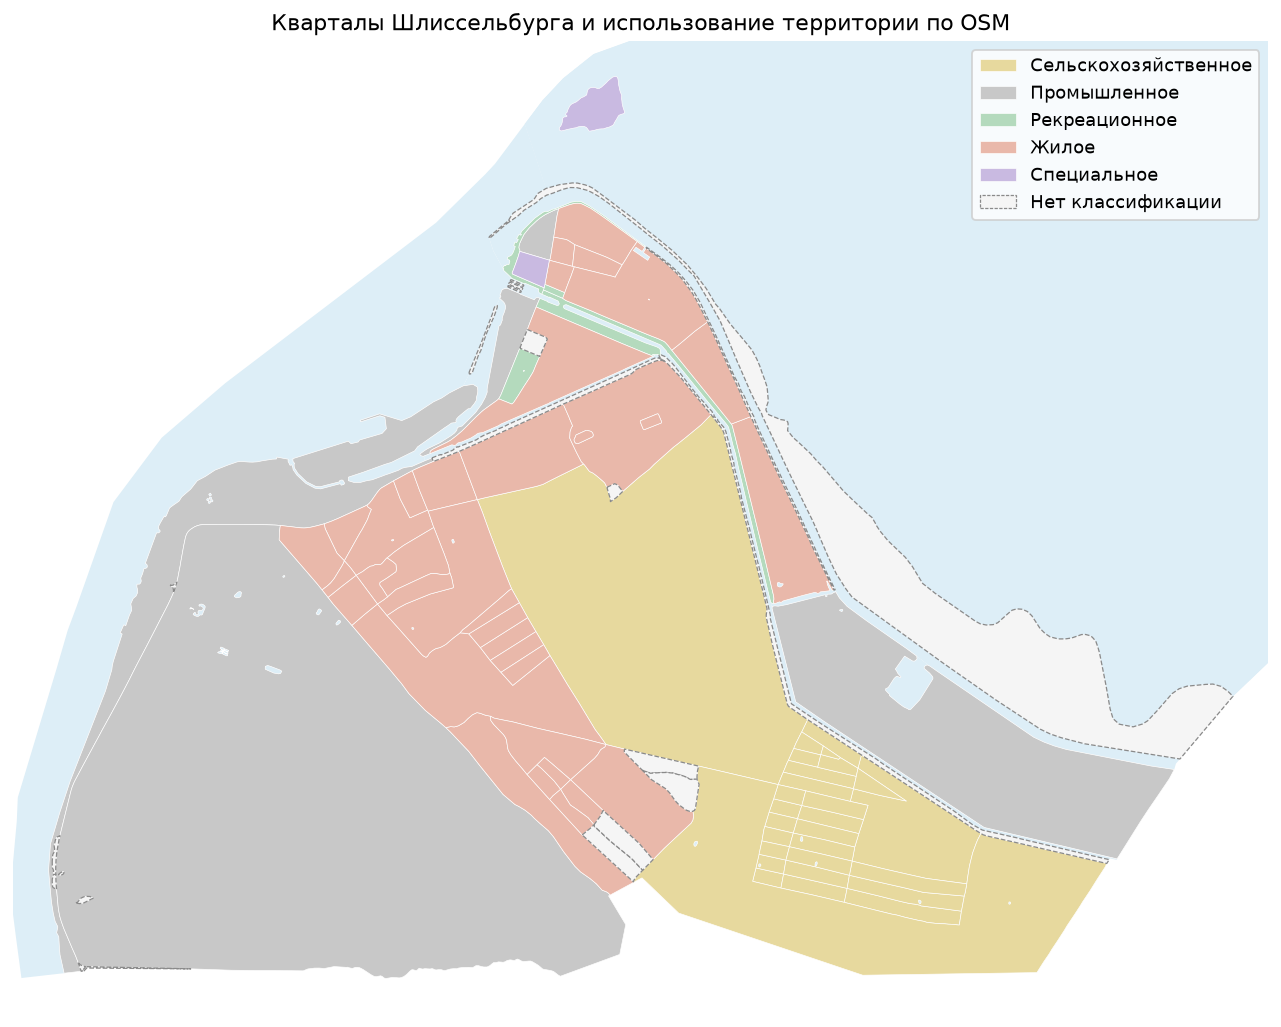

,Доля жилой функции,Доля деловой функции,Доля рекреационной функции,Доля промышленной функции,Доля транспортной функции,Доля специальной функции,Доля сельскохозяйственной функции,Преобладающая функция,Доля преобладающей функции,"Площадь квартала, м²"
Квартал,,,,,,,,,,
0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,Нет классификации,NaN,7.166804e+04
1,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.941809,Сельскохозяйственное,0.941809,2.581364e+05
2,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.879864,Сельскохозяйственное,0.879864,2.500508e+04
3,0.036561,0.0,0.000482,0.053464,0.0,0.0,0.142521,Сельскохозяйственное,0.142521,1.956868e+06
4,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,Нет классификации,NaN,2.851767e+04


In [5]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse
import shapely

local_crs = CRS
def geometry_parts(frame, allowed):
    frame = frame.copy().explode(index_parts=False).reset_index(drop=True)
    for _ in range(3):
        if not frame.geometry.geom_type.eq('GeometryCollection').any():
            break
        frame = frame.explode(index_parts=False).reset_index(drop=True)
    return frame.loc[frame.geometry.geom_type.isin(allowed) & ~frame.geometry.is_empty].reset_index(drop=True)

roads_m = geometry_parts(layers['roads'].to_crs(CRS), ['LineString','MultiLineString'])
railways_m = geometry_parts(layers['railways'].to_crs(CRS), ['LineString','MultiLineString'])
water_m = geometry_parts(layers['water'].to_crs(CRS), ['Polygon','MultiPolygon','LineString','MultiLineString'])
water_polygons = geometry_parts(water_m, ['Polygon','MultiPolygon'])
WATER_POLYGONS = water_polygons.geometry.union_all() if len(water_polygons) else Polygon()
lines, polygons = preprocess_urban_objects(roads_m, railways_m, water_m)
blocks = cut_urban_blocks(boundary_m[['geometry']], lines, polygons)
blocks = blocks.loc[~blocks.geometry.is_empty & blocks.area.gt(0)].copy().reset_index(drop=True)
blocks.index = pd.Index(range(len(blocks)), dtype=int)
block_ids = blocks.index.copy()
assert len(blocks) > 0 and blocks.geometry.is_valid.all()
assert blocks.geometry.geom_type.eq('Polygon').all()
assert blocks.crs == CRS
blocks_union = blocks.geometry.union_all()
overlap_area = 0.0
for left, right in zip(*blocks.sindex.query(blocks.geometry, predicate='intersects')):
    if left < right:
        overlap_area += float(blocks.geometry.iloc[left].intersection(blocks.geometry.iloc[right]).area)
assert overlap_area == 0, f'Перекрытие кварталов: {overlap_area} м²'
water_intersection = blocks_union.intersection(WATER_POLYGONS)
water_overlap = float(water_intersection.area)
water_coordinate_roundoff = 0.0
water_area_roundoff = 0.0
water_boundary_distance = 0.0
if not WATER_POLYGONS.is_empty:
    minx, miny, maxx, maxy = WATER_POLYGONS.bounds
    water_coordinate_roundoff = math.hypot(math.ulp(max(abs(minx), abs(maxx))),
                                          math.ulp(max(abs(miny), abs(maxy))))
    water_check = geometry_parts(gpd.GeoDataFrame(geometry=[water_intersection], crs=CRS), ['Polygon','MultiPolygon'])
    if len(water_check):
        coordinates = shapely.get_coordinates(water_check.geometry.to_numpy())
        water_boundary_distance = float(shapely.distance(shapely.points(coordinates), WATER_POLYGONS.boundary).max())
        water_area_roundoff = float(water_check.length.sum()) * water_coordinate_roundoff
assert water_boundary_distance <= water_coordinate_roundoff, 'Пересечение с водой выходит за машинный шаг координат.'
assert water_overlap <= water_area_roundoff, f'Вода осталась внутри кварталов: {water_overlap} м²'
outside_boundary_area = float(blocks_union.difference(boundary_m.geometry.union_all()).area)

rules = {
    'commercial':LandUse.BUSINESS,'industrial':LandUse.INDUSTRIAL,'cemetery':LandUse.SPECIAL,
    'garages':LandUse.INDUSTRIAL,'residential':LandUse.RESIDENTIAL,'retail':LandUse.BUSINESS,
    'grass':LandUse.RECREATION,'farmland':LandUse.AGRICULTURE,'construction':LandUse.SPECIAL,
    'brownfield':LandUse.INDUSTRIAL,'forest':LandUse.RECREATION,'recreation_ground':LandUse.RECREATION,
    'religious':LandUse.SPECIAL,'flowerbed':LandUse.RECREATION,'military':LandUse.SPECIAL,
    'landfill':LandUse.TRANSPORT,'allotments':LandUse.AGRICULTURE,'orchard':LandUse.AGRICULTURE,
    'meadow':LandUse.RECREATION,'village_green':LandUse.RECREATION,'railway':LandUse.TRANSPORT
}
zones = geometry_parts(layers['landuse'].to_crs(CRS), ['Polygon','MultiPolygon'])
zones = zones[['geometry','landuse']].rename(columns={'landuse':'functional_zone'})
unknown_zones = sorted(set(zones['functional_zone'].dropna().astype(str)) - set(rules))
known_zones = zones.loc[zones.functional_zone.isin(rules)].reset_index(drop=True)
if len(known_zones):
    zone_categories = known_zones.functional_zone.map(rules)
    merged_zones = []
    for category in LandUse:
        same_function = known_zones.loc[zone_categories.eq(category)]
        if len(same_function):
            merged_zones.append({'functional_zone': category.value,
                                 'geometry': same_function.geometry.union_all()})
    known_zones = gpd.GeoDataFrame(merged_zones, geometry='geometry', crs=CRS)
    category_rules = {category.value: category for category in LandUse}
    blocks = assign_land_use(blocks, known_zones, category_rules)
else:
    for category in ['residential','business','recreation','industrial','transport','special','agriculture']:
        blocks[category] = 0.0
    blocks['land_use'] = None
    blocks['share'] = 0.0
blocks['land_use'] = blocks['land_use'].map(lambda value: value.value if isinstance(value,enum.Enum) else value)
assert blocks.index.equals(block_ids)
blocks['site_area'] = blocks.area
save_geojson(blocks, PREPARED / 'blocks.geojson', keep_index=True)
save_geojson(water_polygons, PREPARED / 'water.geojson')
stage('blocks', status='saved', geometry_source='OpenStreetMap barriers / BlocksNet cut_urban_blocks',
      source_files=['data/raw/boundary.geojson', 'data/raw/roads.geojson',
                    'data/raw/railways.geojson', 'data/raw/water.geojson'],
      block_id_rule='zero-based consecutive generated polygon index',
      landuse_preparation='union of OSM zones within each LandUse category',
      count=len(blocks), area_km2=blocks.site_area.sum()/1e6,
      union_area_km2=blocks_union.area/1e6, outside_osm_boundary_m2=outside_boundary_area,
      overlap_area_m2=overlap_area, water_overlap_m2=water_overlap,
      water_boundary_roundoff_m=water_coordinate_roundoff,
      water_area_roundoff_bound_m2=water_area_roundoff,
      water_intersection_max_boundary_distance_m=water_boundary_distance,
      unknown_landuse=unknown_zones, max_landuse_share=float(blocks['share'].max()))
print(f'Кварталов по барьерам OSM: {len(blocks)}; сумма площадей: {blocks.site_area.sum()/1e6:.6f} км²; площадь объединения: {blocks_union.area/1e6:.6f} км².')
print(f'Повторно покрытая площадь: {overlap_area:.3f} м²; пересечение с водой OSM: {water_overlap:.3f} м²; за границей OSM: {outside_boundary_area:.3f} м².')
print('Не классифицированные теги landuse:', unknown_zones)
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_facecolor(MAP_STYLE['mapBackground'])
if len(water_polygons): water_polygons.plot(ax=ax, color=MAP_STYLE['water'], zorder=0)
blocks.plot(ax=ax, column='land_use', categories=MAP_CATEGORIES['land_use'],
    cmap=MAP_CATEGORY_CMAPS['land_use'], legend=True, edgecolor=MAP_STYLE['blockBoundary'], linewidth=0.35,
    missing_kwds={'color':MAP_STYLE['missing'],'edgecolor':MAP_STYLE['missingOutline'],'linestyle':'--','linewidth':0.7,'label':'Нет классификации'})
xmin,ymin,xmax,ymax = blocks.total_bounds
margin = 0.03*max(xmax-xmin,ymax-ymin)
ax.set_xlim(xmin-margin,xmax+margin); ax.set_ylim(ymin-margin,ymax+margin)
legend_labels = {'agriculture':'Сельскохозяйственное','industrial':'Промышленное','recreation':'Рекреационное',
    'residential':'Жилое','special':'Специальное','transport':'Транспортное','business':'Деловое'}
for label in ax.get_legend().get_texts():
    label.set_text(legend_labels.get(label.get_text(),label.get_text()))
ax.set_title('Кварталы Шлиссельбурга и использование территории по OSM')
ax.set_axis_off(); fig.tight_layout(); fig.savefig(RESULTS/'blocks.png', dpi=180); plt.show()
landuse_view=blocks.drop(columns='geometry').head().copy()
landuse_view['land_use']=landuse_view.land_use.map(legend_labels).fillna('Нет классификации')
display_table(landuse_view,index_label='Квартал')

## 4. Здания и оценка населения

Объект здания имеет контур на плане и, когда это указано в OSM, тип и этажность. В подготовленной таблице одна строка соответствует одному площадному объекту OSM; составной контур не разбивается на несколько зданий. Число таких объектов характеризует состав карты, который может отличаться от числа отдельно учитываемых физических построек.

Площадь контура называется **пятном здания**. У трёхэтажного здания с пятном 1 000 м² расчётная поэтажная площадь равна 3 000 м². Так различаются занятая на плане земля и площадь всех этажей.

| Поле | Что означает и как получено | Единица |
| --- | --- | --- |
| `building_count` | Число объектов зданий, назначенных кварталу | объектов |
| `is_living` | Для отдельного здания показывает, отнесла ли модель его к жилью. Для квартала содержит число таких объектов | признак у здания; объектов в квартале |
| `number_of_floors` | У здания этажность из OSM либо принятый один этаж; в квартале сумма этажностей всех назначенных зданий | сумма этажностей |
| `footprint_area` | Сумма площадей контуров зданий на плане | м² |
| `build_floor_area` | Сумма произведений пятна каждого здания на его этажность | м² |
| `living_area` | Расчётная жилая площадь при принятой классификации и доле 0,9 поэтажной площади жилого здания | м² |
| `non_living_area` | Прочая расчётная площадь: остаток поэтажной площади после вычитания расчётной жилой площади | м² |
| `population` | Оценка жителей по жилой площади каждого здания, затем сумма по кварталу | человек |

Жилыми признаны явные теги `residential`, `house`, `apartments`, `detached`, `terrace`, `dormitory`, как в учебном примере. Тег `building=yes` подтверждает наличие контура, но не уточняет назначение. Пример не относит его к жилью. Поэтому часть `non_living_area` в этой модели получена из **неизвестного назначения**, а не из подтверждённой промышленной или деловой функции. Это допущение влияет на население, долю жилья и обе классификации застройки.

Для жилого здания цепочка оценки имеет вид: пятно × этажность → поэтажная площадь → умножение на 0,9 → деление на 30 м²/чел. Частное округлено вниз отдельно для каждого жилого здания; при нулевом результате библиотека назначает одного жителя. Остальным объектам в этой реализации назначено нулевое модельное население. Для объектов на садовых территориях `allotments` постоянное население также не назначается. Эти нули являются правилами модели, а не результатами обследования заселённости.

При отсутствии этажности принят один этаж. Признаки `floors_estimated` и `population_estimated` в слое зданий позволяют отличить оценку от известного значения. Ниже показаны число восстановленных этажностей, масштаб неопределённого назначения и квартальные суммы.

Штатная функция BlocksNet относит здание к кварталу по точке `representative_point`, которая гарантированно находится внутри контура здания. В квартал целиком добавляются все расчётные атрибуты здания. Перед агрегацией проверяется, что эта точка попала не более чем в один полигон квартала; неоднозначное попадание останавливает расчёт с указанием объекта и кварталов. Объекты вне кварталов сохранены отдельно и не добавлены к квартальным итогам. Число объектов и суммы атрибутов сверяются с подготовленным слоем. Население и площади зданий рассчитываются по OSM; из геоданных предыдущей учебной работы они не переносятся.

In [6]:
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

def numeric_column(frame, name):
    series = frame[name] if name in frame else pd.Series(np.nan, index=frame.index)
    return pd.to_numeric(series, errors='coerce').astype(float)

def check_unique_block_assignment(blocks_frame, objects_frame):
    assert blocks_frame.index.is_unique and objects_frame.index.is_unique
    points = gpd.GeoDataFrame(geometry=objects_frame.geometry.representative_point(), crs=objects_frame.crs)
    joined = points.sjoin(blocks_frame[['geometry']], how='inner', predicate='intersects')
    repeated = joined.loc[joined.index.duplicated(keep=False)]
    if len(repeated):
        details = []
        for object_id, rows in repeated.groupby(level=0):
            key = objects_frame.loc[object_id, 'osm_key'] if 'osm_key' in objects_frame else str(object_id)
            details.append(f'{key}: кварталы {rows.index_right.tolist()}')
        raise ValueError('Неоднозначное назначение по representative_point. Проверьте границы кварталов: ' + '; '.join(details))
    return joined.index

def verify_aggregation_balance(aggregated, source, excess, columns):
    assert int(aggregated['count'].sum()) + len(excess) == len(source)
    for column in columns:
        values = pd.to_numeric(source[column], errors='raise').fillna(0).to_numpy(dtype=float)
        expected = math.fsum(values)
        actual = math.fsum(aggregated[column].astype(float)) + math.fsum(excess[column].fillna(0).astype(float))
        # The summation error bound depends on machine precision and the actual input size.
        n_eps = max(1, len(values)) * np.finfo(float).eps
        roundoff = n_eps / (1 - n_eps) * math.fsum(abs(value) for value in values)
        assert abs(actual - expected) <= roundoff, f'Нарушен баланс {column}: {actual} вместо {expected}'

building_raw = layers['buildings'].to_crs(CRS).copy()
building_raw = building_raw.loc[building_raw.geometry.geom_type.isin(['Polygon','MultiPolygon'])].reset_index(drop=True)
building_raw = building_raw.loc[~building_raw.geometry.to_wkb().duplicated()].reset_index(drop=True)
if building_raw.empty:
    raise ValueError('Нет площадных зданий. Проверьте исходный слой и границу перед оценкой населения.')
living_tags = ['residential','house','apartments','detached','terrace','dormitory']
building_raw['is_living'] = building_raw['building'].isin(living_tags)
garden_zones = zones.loc[zones.functional_zone.eq('allotments')]
garden_union = garden_zones.geometry.union_all() if len(garden_zones) else Polygon()
building_raw['in_allotments'] = building_raw.geometry.representative_point().within(garden_union)
building_raw.loc[building_raw.in_allotments, 'is_living'] = False
building_raw['number_of_floors'] = numeric_column(building_raw, 'building:levels').where(lambda x: x > 0)
floors_estimated = building_raw.number_of_floors.isna()
buildings = impute_buildings(building_raw, default_living_demand=LIVING_AREA_PER_PERSON)
buildings.loc[~buildings.is_living, 'population'] = 0.0
buildings['osm_key'] = building_raw['osm_key'].values
buildings['building_tag'] = building_raw['building'].values
buildings['floors_estimated'] = floors_estimated.values
buildings['population_estimated'] = True
buildings['in_allotments'] = building_raw['in_allotments'].values
assert buildings.population.ge(0).all()
assert buildings.loc[buildings.in_allotments, 'population'].sum() == 0
save_geojson(buildings, PREPARED/'buildings.geojson')
building_cols = ['geometry','is_living','number_of_floors','footprint_area','build_floor_area','living_area','non_living_area','population']
building_assignment_index = check_unique_block_assignment(blocks, buildings)
building_agg, excess_buildings = aggregate_objects(blocks, buildings[building_cols])
assert set(excess_buildings.index) == set(buildings.index) - set(building_assignment_index)
verify_aggregation_balance(building_agg, buildings, excess_buildings, building_cols[1:])
building_agg = building_agg.rename(columns={'count':'building_count'})
blocks = blocks.join(building_agg.drop(columns='geometry'))
excess_buildings['osm_key'] = buildings.loc[excess_buildings.index,'osm_key']
save_geojson(excess_buildings, PREPARED/'buildings_unassigned.geojson')


unknown_buildings = buildings.building_tag.eq('yes')
unknown_footprint_share = float(buildings.loc[unknown_buildings,'footprint_area'].sum()/buildings.footprint_area.sum())
unknown_floor_share = float(buildings.loc[unknown_buildings,'build_floor_area'].sum()/buildings.build_floor_area.sum())
print(f'Подготовленный слой содержит {count_text(len(buildings),"объект","объекта","объектов")}. Модель отнесла к жилью {count_text(int(buildings.is_living.sum()),"объект","объекта","объектов")}.')
print(f'Назначение building=yes не уточнено у {count_text(int(unknown_buildings.sum()),"объекта","объектов","объектов")}: {number_text(unknown_footprint_share*100,1)}% суммарного пятна и {number_text(unknown_floor_share*100,1)}% поэтажной площади.')
print(f'Один этаж принят при отсутствии этажности у {count_text(int(floors_estimated.sum()),"объекта","объектов","объектов")}. Кварталам не назначено {count_text(len(excess_buildings),"объект","объекта","объектов")}.')
with pd.option_context('display.max_columns',None):
    building_view=buildings[['building_tag','number_of_floors','floors_estimated','is_living','footprint_area','build_floor_area','living_area','non_living_area','population']].head(8).copy()
    for field in ['floors_estimated','is_living']:
        building_view[field]=building_view[field].map({True:'Да',False:'Нет'})
    display_table(building_view,labels={'number_of_floors':'Этажность','is_living':'Признак жилого здания'},index_label='Объект здания')
    display_table(blocks[['building_count','is_living','number_of_floors','footprint_area','build_floor_area','living_area','non_living_area','population']].head(12),index_label='Квартал')

Подготовленный слой содержит 1 844 объекта. Модель отнесла к жилью 170 объектов.
Назначение building=yes не уточнено у 1 440 объектов: 53,3% суммарного пятна и 30,2% поэтажной площади.
Один этаж принят при отсутствии этажности у 1 000 объектов. Кварталам не назначено 5 объектов.


,Тип здания по OSM,Этажность,Этажность принята по допущению,Признак жилого здания,"Пятно зданий, м²","Поэтажная площадь, м²","Расчётная жилая площадь, м²","Прочая расчётная площадь, м²","Модельное население, чел."
Объект здания,,,,,,,,,
0,apartments,2.0,Нет,Да,1378.360616,2756.721232,2481.049109,275.672123,82.0
1,yes,1.0,Да,Нет,466.493072,466.493072,0.000000,466.493072,0.0
2,yes,1.0,Да,Нет,231.046587,231.046587,0.000000,231.046587,0.0
3,yes,1.0,Да,Нет,314.174756,314.174756,0.000000,314.174756,0.0
4,yes,1.0,Да,Нет,189.450057,189.450057,0.000000,189.450057,0.0
5,yes,1.0,Да,Нет,341.534737,341.534737,0.000000,341.534737,0.0
6,yes,1.0,Да,Нет,1073.947872,1073.947872,0.000000,1073.947872,0.0
7,yes,1.0,Да,Нет,486.501760,486.501760,0.000000,486.501760,0.0


,Объектов зданий,Жилых объектов,Сумма этажностей,"Пятно зданий, м²","Поэтажная площадь, м²","Расчётная жилая площадь, м²","Прочая расчётная площадь, м²","Модельное население, чел."
Квартал,,,,,,,,
0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0
1,62.0,0.0,62.0,4632.135015,4632.135015,0.000000,4632.135015,0.0
2,8.0,0.0,8.0,379.783909,379.783909,0.000000,379.783909,0.0
3,110.0,15.0,129.0,31477.458518,58341.705287,14064.984367,44276.720920,461.0
4,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0
5,76.0,0.0,103.0,96132.374402,348339.956622,0.000000,348339.956622,0.0
6,21.0,0.0,32.0,17904.897003,41967.360524,0.000000,41967.360524,0.0
7,1.0,0.0,1.0,199.063308,199.063308,0.000000,199.063308,0.0
8,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0


## 5. Учебные корпуса школы и вместимость

Из геоданных учебной работы «Моделирование территории» взято положение двух существующих корпусов школы № 1. Вместимость учебных корпусов принята по сведениям, опубликованным на сайтах образовательных организаций: **683 и 934 места, всего 1 617**. Одинаковое официальное наименование в исходных записях связывает корпуса с одной школой.

| Поле | Смысл | Единица |
| --- | --- | --- |
| `school_count` | Число учебных корпусов, назначенных кварталу | корпусов |
| `capacity` | Сумма переданной вместимости этих корпусов | мест |
| `capacity_estimated` | Здесь `False`: библиотечная подстановка вместимости не выполнялась | да/нет в слое школ |
| `capacity_source` | `manual_existing_state`: значение загружено из локальной копии геоданных существующих школ | обозначение способа загрузки |

`school_count=2` означает два корпуса одной школы. Сведения с сайтов образовательных организаций перенесены в геоданные предыдущей учебной работы. Дата состояния этих сведений не установлена; их актуальность отдельно не проверялась. В расчёте используются переданные значения вместимости.

Назначение корпуса кварталу выполняется штатной функцией BlocksNet по `representative_point`, точке внутри его контура. До суммирования вместимости проверяется единственность попадания; при неоднозначности расчёт останавливается. Корпуса вне кварталов сохраняются отдельно. Проверяются баланс числа корпусов и баланс вместимости.

In [7]:
schools = layers['schools'].to_crs(CRS).copy().reset_index(drop=True)
if schools.empty:
    raise ValueError('Слой существующих школьных корпусов пуст.')
if not schools.geometry.geom_type.isin(['Point','Polygon','MultiPolygon']).all():
    raise ValueError('В слое школьных корпусов обнаружена неподдерживаемая геометрия.')
if schools.geometry.is_empty.any() or not schools.geometry.is_valid.all():
    raise ValueError('Геометрия школьных корпусов требует проверки.')
schools['capacity'] = pd.to_numeric(schools['capacity'], errors='coerce')
if schools.capacity.isna().any() or schools.capacity.lt(0).any():
    raise ValueError('В исходных геоданных должна быть указана вместимость каждого корпуса.')
if schools['osm_key'].duplicated().any():
    raise ValueError('В слое существующих школ повторяется идентификатор корпуса.')
schools['capacity_estimated'] = False
schools['capacity_source'] = 'manual_existing_state'
schools['capacity_source_label'] = 'Сайты образовательных организаций'
school_assignment_index = check_unique_block_assignment(blocks, schools)
school_agg, excess_schools = aggregate_objects(blocks, schools[['geometry','capacity']])
assert set(excess_schools.index) == set(schools.index) - set(school_assignment_index)
verify_aggregation_balance(school_agg, schools, excess_schools, ['capacity'])
blocks['school_count'] = school_agg['count']
blocks['capacity'] = school_agg['capacity']
assert math.isclose(float(schools.capacity.sum()), float(manual_school_metadata['capacity_total']))
assert int(blocks.school_count.sum()) + len(excess_schools) == len(schools)
assert math.isclose(float(blocks.capacity.sum()+excess_schools.capacity.sum()), float(schools.capacity.sum()))
assert math.isclose(float(blocks.population.sum()+excess_buildings.population.sum()), float(buildings.population.sum()), abs_tol=1e-6)
save_geojson(schools, PREPARED/'schools.geojson')
excess_schools['osm_key'] = schools.loc[excess_schools.index,'osm_key']
excess_schools['capacity_source'] = 'manual_existing_state'
save_geojson(excess_schools, PREPARED/'schools_unassigned.geojson')


school_view=schools[['name','osm_key','capacity','capacity_source_label']].copy()
school_view['capacity_source_label']='Сайты образовательных организаций'
display_table(school_view,index_label='Корпус')
display_table(blocks.loc[blocks.school_count.gt(0),['school_count','capacity','population']],index_label='Квартал')
print(f'В исходных геоданных {count_text(len(schools),"учебный корпус","учебных корпуса","учебных корпусов")} одной школы; суммарная вместимость {count_text(schools.capacity.sum(),"место","места","мест")}.')
print('Вместимость учебных корпусов принята по сведениям, опубликованным на сайтах образовательных организаций. Дата состояния этих сведений не установлена.')

,Название,Идентификатор OSM,"Вместимость, мест",Источник вместимости
Корпус,,,,
0,Школа № 1,way/116432510,683,Сайты образовательных организаций
1,Школа № 1 (старшие классы),way/285212050,934,Сайты образовательных организаций


,Учебных корпусов,"Вместимость, мест","Модельное население, чел."
Квартал,,,
3,1.0,934.0,461.0
24,1.0,683.0,3466.0


В исходных геоданных 2 учебных корпуса одной школы; суммарная вместимость 1 617 мест.
Вместимость учебных корпусов принята по сведениям, опубликованным на сайтах образовательных организаций. Дата состояния этих сведений не установлена.


## 6. Плотность застройки

Показатели плотности позволяют сопоставлять кварталы разной площади. Обозначим площадь квартала **S**, суммарное пятно зданий **B**, поэтажную площадь **F**, жилую площадь **R**, прочую расчётную площадь **N**. Все пять величин измерены в м².

| Поле | Расчёт | Как читать |
| --- | --- | --- |
| `fsi`, FSI | F / S | Сколько м² поэтажной площади приходится на 1 м² территории. FSI 0,6 означает 6 000 м² этажей на участке 1 га |
| `gsi`, GSI | B / S | Доля земли под контурами зданий. 0,2 соответствует 20% площади квартала |
| `mxi`, MXI | R / F | Расчётная доля жилья в поэтажной площади. 0,75 соответствует 75% |
| `l`, L | F / B | Средняя расчётная этажность с весом пятна: крупные здания влияют сильнее маленьких |
| `osr`, OSR | (S-B) / F | Незастроенная площадь квартала на 1 м² поэтажной площади |
| `share_living` | R / B | Жилая площадь на 1 м² пятна зданий |
| `share_non_living` | N / B | Прочая расчётная площадь на 1 м² пятна |

Показатели являются отношениями площадей. У GSI и MXI принято представление долей от 0 до 1; библиотека ограничивает их этим диапазоном, а L ограничивает снизу единицей. `share_living` и `share_non_living` могут превышать 1, потому что учитывают несколько этажей над одним пятном. Они не являются долями земли. Например, значение 5 означает 5 м² соответствующей площади на 1 м² пятна.

OSR характеризует всю незастроенную часть квартала. В неё могут входить разные территории, поэтому высокое значение не доказывает наличие благоустроенного общественного пространства. MXI зависит от принятой классификации назначения зданий и доли жилья 0,9. У незастроенного квартала отношения с нулевой поэтажной площадью или пятном могут быть неопределены.

Поле `number_of_floors` содержит сумму этажностей всех зданий, а L усредняет этажность с весом пятна. Для сравнения этажности кварталов используется L. В следующей таблице приведены все семь отношений, а после основных расчётов разобраны несколько кварталов с разными значениями.

,"Площадь квартала, м²","Пятно зданий, м²","Поэтажная площадь, м²","Расчётная жилая площадь, м²","Прочая расчётная площадь, м²","FSI, м²/м²","GSI, доля","MXI, доля","L, этажей","OSR, м²/м²","Жилая площадь к пятну, м²/м²","Прочая расчётная площадь к пятну, м²/м²"
Квартал,,,,,,,,,,,,
0,7.166804e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
1,2.581364e+05,4632.135015,4632.135015,0.000000,4632.135015,0.017945,0.017945,0.000000,1.000000,54.727315,0.000000,1.000000
2,2.500508e+04,379.783909,379.783909,0.000000,379.783909,0.015188,0.015188,0.000000,1.000000,64.840284,0.000000,1.000000
3,1.956868e+06,31477.458518,58341.705287,14064.984367,44276.720920,0.029814,0.016086,0.241079,1.853444,33.001951,0.446827,1.406617
4,2.851767e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
5,6.615419e+05,96132.374402,348339.956622,0.000000,348339.956622,0.526558,0.145316,0.000000,3.623545,1.623154,0.000000,3.623545
6,8.521738e+04,17904.897003,41967.360524,0.000000,41967.360524,0.492474,0.210109,0.000000,2.343904,1.603925,0.000000,2.343904
7,8.720191e+04,199.063308,199.063308,0.000000,199.063308,0.002283,0.002283,0.000000,1.000000,437.061180,0.000000,1.000000
8,1.886771e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN


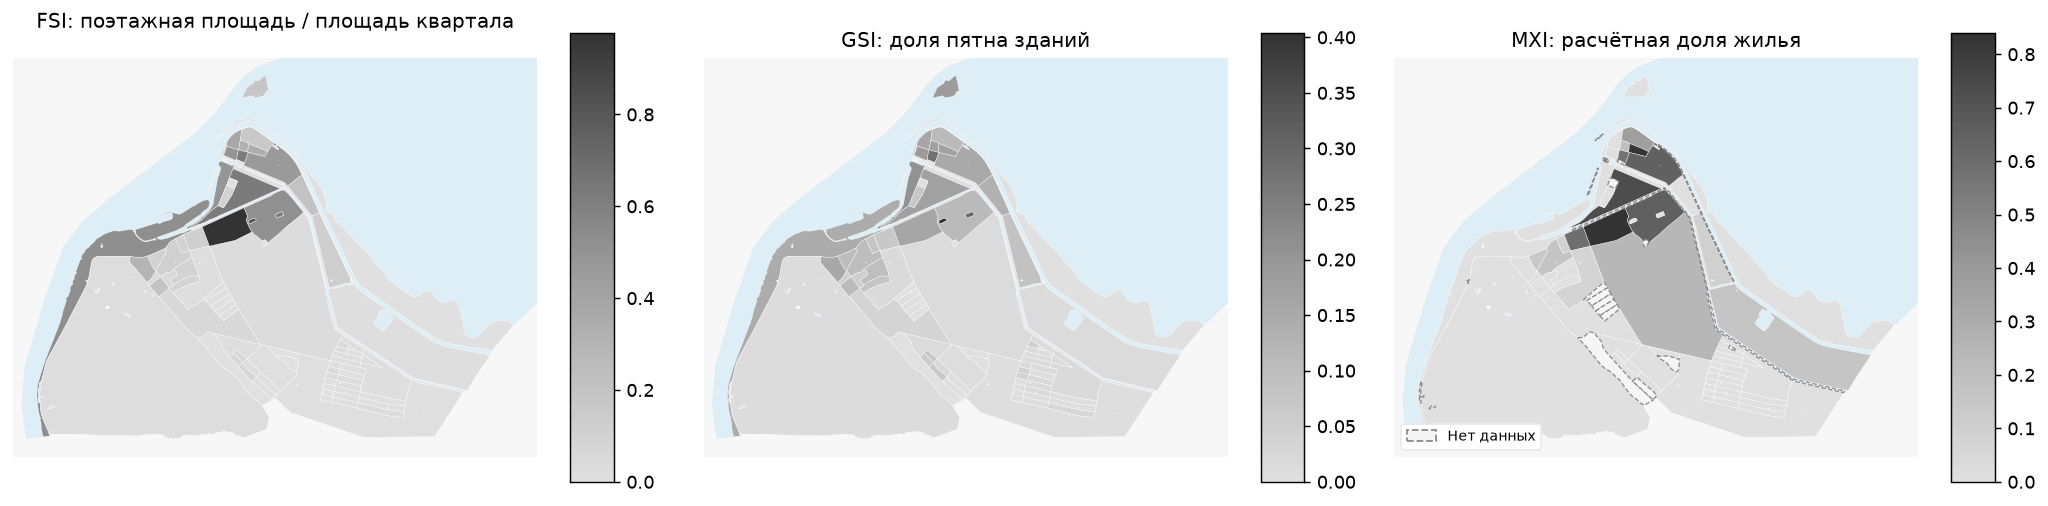

In [8]:
density = calculate_density_indicators(blocks)
density_fields = ['fsi','gsi','mxi','l','osr','share_living','share_non_living']
blocks = blocks.join(density[density_fields])

with pd.option_context('display.max_columns',None):
    display_table(blocks[['site_area','footprint_area','build_floor_area','living_area','non_living_area']+density_fields].head(12),index_label='Квартал')
from matplotlib.patches import Patch
fig,axes=plt.subplots(1,3,figsize=(16,7))
for ax,field,title in zip(axes,['fsi','gsi','mxi'],['FSI: поэтажная площадь / площадь квартала','GSI: доля пятна зданий','MXI: расчётная доля жилья']):
    blocks.plot(ax=ax,column=field,cmap=MAP_NUMERIC_CMAP,legend=True,edgecolor=MAP_STYLE['blockBoundary'],linewidth=0.2,missing_kwds={'color':MAP_STYLE['missing'],'edgecolor':MAP_STYLE['missingOutline'],'linestyle':'--','linewidth':0.7})
    plot_water_background(ax)
    if blocks[field].isna().any():
        ax.legend(handles=[Patch(facecolor=MAP_STYLE['missing'],edgecolor=MAP_STYLE['missingOutline'],linestyle='--',label='Нет данных')],
            loc='lower left',fontsize=8,framealpha=1,facecolor=MAP_STYLE['ui']['panel'],edgecolor=MAP_STYLE['ui']['grid'])
    ax.set_title(title,fontsize=11); ax.set_axis_off()
fig.tight_layout(); fig.savefig(RESULTS/'density_metrics.png',dpi=170); plt.show()

## 7. Расчётные типы застройки

**Морфотип** здесь означает класс квартала по численным характеристикам застройки. В используемой реализации BlocksNet оба способа используют L, FSI и MXI. Spacematrix определяет тип по характеристикам группы сходных кварталов, а «Стрелка» применяет фиксированные правила к показателям каждого квартала отдельно.

**[Spacematrix в BlocksNet](https://github.com/aimclub/blocksnet/blob/v1.0.0.a9/blocksnet/analysis/morphotypes/spacematrix.py)** сначала объединяет похожие кварталы в группы, или кластеры. Признаки приведены к сопоставимому масштабу, затем применён алгоритм KMeans. Задано 11 групп и фиксированное начальное состояние 42, чтобы повторное выполнение давало тот же результат. Для каждой группы вычислены медианные L, FSI и MXI, по которым назначено словесное описание. Каждый квартал получает описание своей группы. Номер кластера является идентификатором, а не оценкой качества территории.

В этой реализации названия этажности меняются при L = 3, 6, 10 и 17. При FSI меньше 1 группа получает подпись «низкая плотность», а при FSI от 2 получает подпись «высокая плотность»; в промежутке отдельная подпись плотности опущена. По медианному MXI группа имеет малую долю жилья при MXI < 0,22, смешанный тип при 0,22 ≤ MXI < 0,55, преимущественно жилой при MXI ≥ 0,55. Поэтому разные кластеры могут иметь одинаковое словесное название.

**[Классификация «Стрелки» в BlocksNet](https://github.com/aimclub/blocksnet/blob/v1.0.0.a9/blocksnet/analysis/morphotypes/strelka.py)** применяет правила непосредственно к каждому кварталу. Группы этажности разделены при L = 4 и 9, затем класс уточняется по его FSI и MXI. Например, для малоэтажной группы MXI < 0,05 даёт тип с малой долей жилья; при большей доле жилья и FSI ≤ 0,1 получается модель индивидуальной застройки. Это другие границы и другой уровень применения правил, поэтому названия двух классификаторов могут различаться.

| Поле | Значение |
| --- | --- |
| `spacematrix_cluster` | Номер группы похожих кварталов |
| `spacematrix_morphotype` | Описание по медианным характеристикам группы Spacematrix |
| `strelka_morphotype` | Класс по характеристикам самого квартала |

На картах названия переведены на русский; в исходных результатах сохранены названия библиотеки. У незастроенных кварталов класс не назначен. Неполное назначение зданий влияет на MXI, поэтому подпись `non-residential` читается как малая расчётная доля жилья **при принятом правиле обработки OSM**. Она не подтверждает фактическое отсутствие жилья. В выводах приведены конкретные примеры различий двух способов.

,L,FSI,MXI,Расчётный тип
Кластер,,,,
0,1.719172,0.121578,0.368161,"Малоэтажная, низкая плотность, смешанный тип"
1,1.344823,0.102116,0.046342,"Малоэтажная, низкая плотность, малая расчётная..."
2,3.311406,0.543852,0.689714,"Среднеэтажная, низкая плотность, преимуществен..."
3,3.623545,0.526558,0.000000,"Среднеэтажная, низкая плотность, малая расчётн..."
4,6.024172,0.977344,0.839693,"Повышенная средняя этажность, низкая плотность..."
5,2.121969,0.347547,0.000000,"Малоэтажная, низкая плотность, малая расчётная..."
6,1.987118,0.338829,0.828901,"Малоэтажная, низкая плотность, преимущественно..."
7,2.000000,0.709698,0.000000,"Малоэтажная, низкая плотность, малая расчётная..."
8,2.265154,0.628119,0.576884,"Малоэтажная, низкая плотность, преимущественно..."


,Кластер Spacematrix,Тип Spacematrix,Тип Стрелки
Квартал,,,
0,<NA>,Не классифицировано,Не классифицировано
1,9,"Малоэтажная, низкая плотность, малая расчётная...","Малоэтажная, малая расчётная доля жилья"
2,9,"Малоэтажная, низкая плотность, малая расчётная...","Малоэтажная, малая расчётная доля жилья"
3,0,"Малоэтажная, низкая плотность, смешанный тип",Модель индивидуальной застройки
4,<NA>,Не классифицировано,Не классифицировано
5,3,"Среднеэтажная, низкая плотность, малая расчётн...","Малоэтажная, малая расчётная доля жилья"
6,5,"Малоэтажная, низкая плотность, малая расчётная...","Малоэтажная, малая расчётная доля жилья"
7,9,"Малоэтажная, низкая плотность, малая расчётная...","Малоэтажная, малая расчётная доля жилья"
8,<NA>,Не классифицировано,Не классифицировано


,Кварталов
strelka_morphotype,
"Малоэтажная, малая расчётная доля жилья",54
Не классифицировано,27
Малоэтажная модель,11
Модель индивидуальной застройки,3
Среднеэтажная модель,2


Классифицировано 70 кварталов, кластеров Spacematrix 11, разных названий 6; типов Стрелки 4.


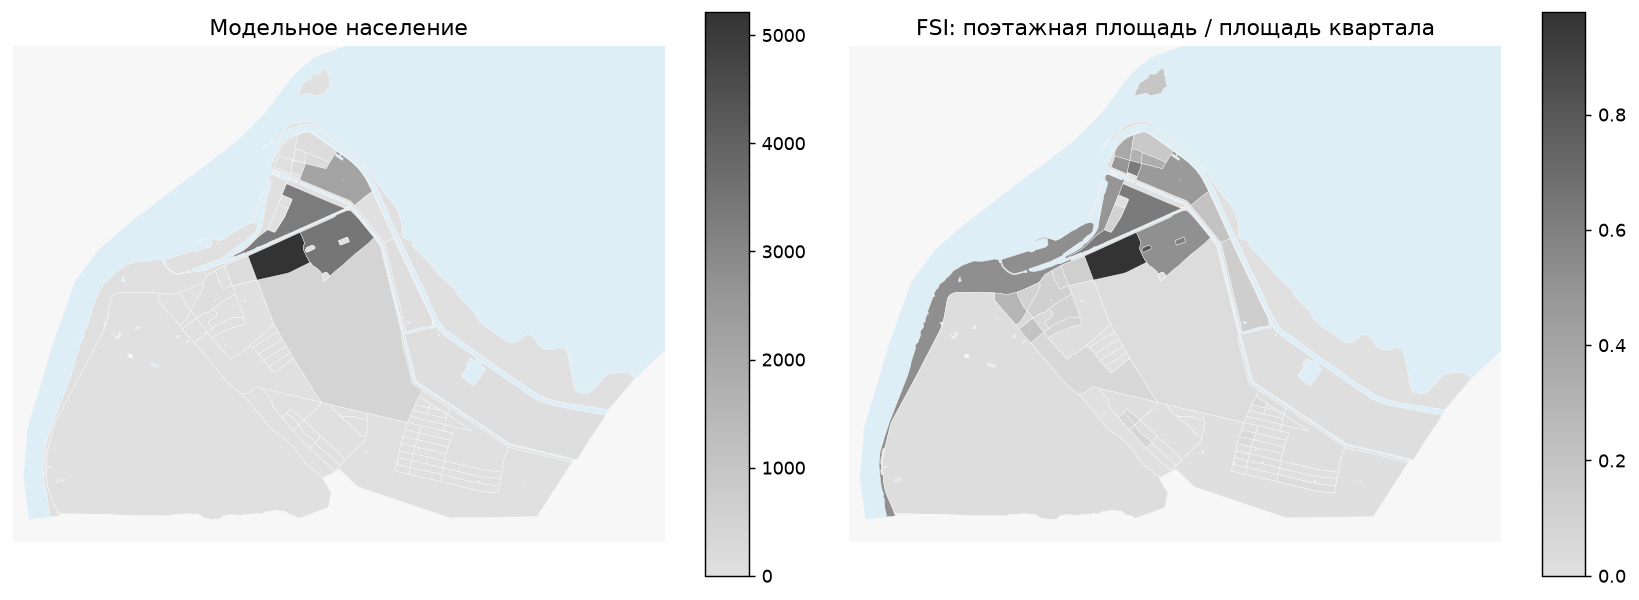

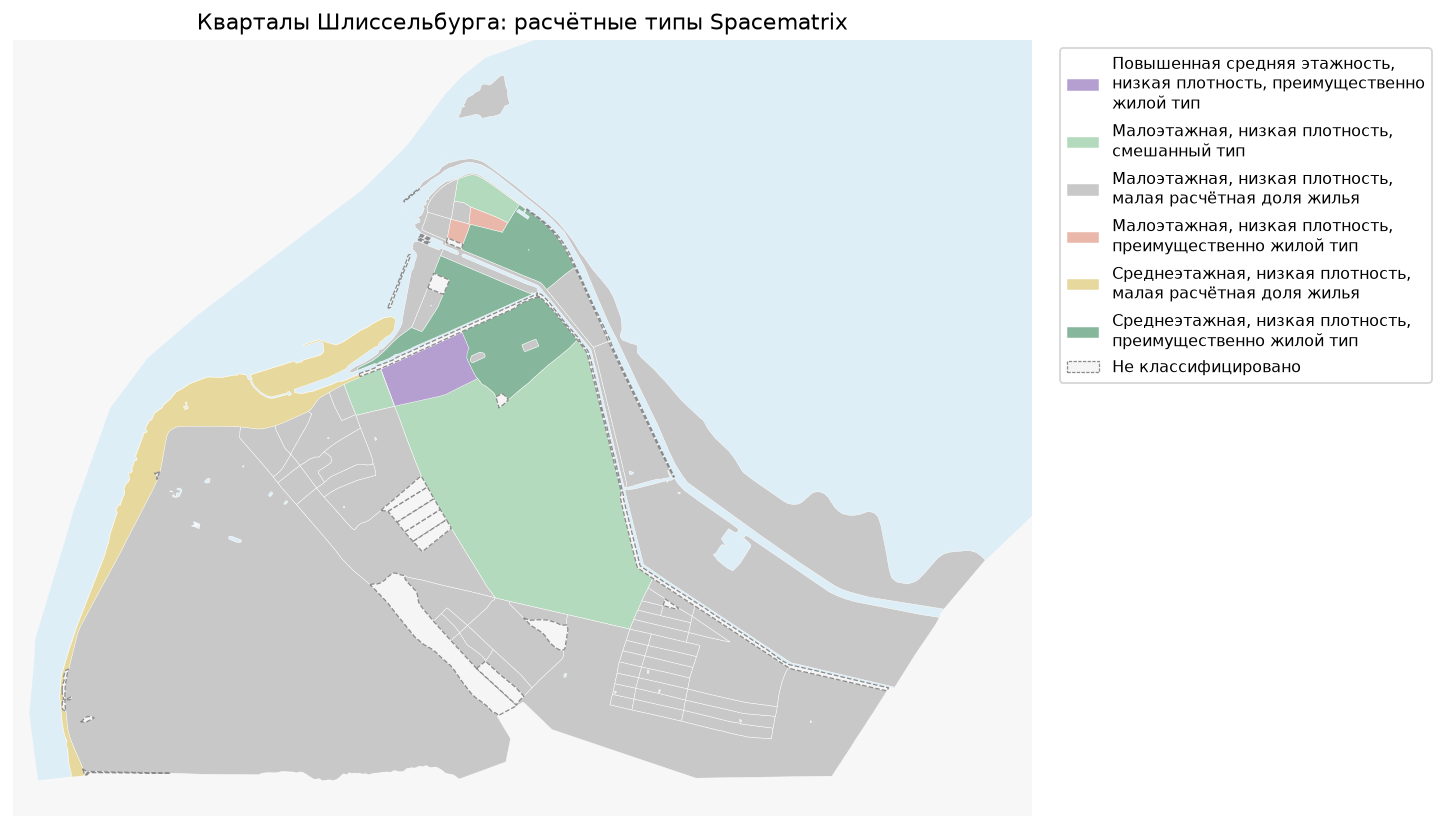

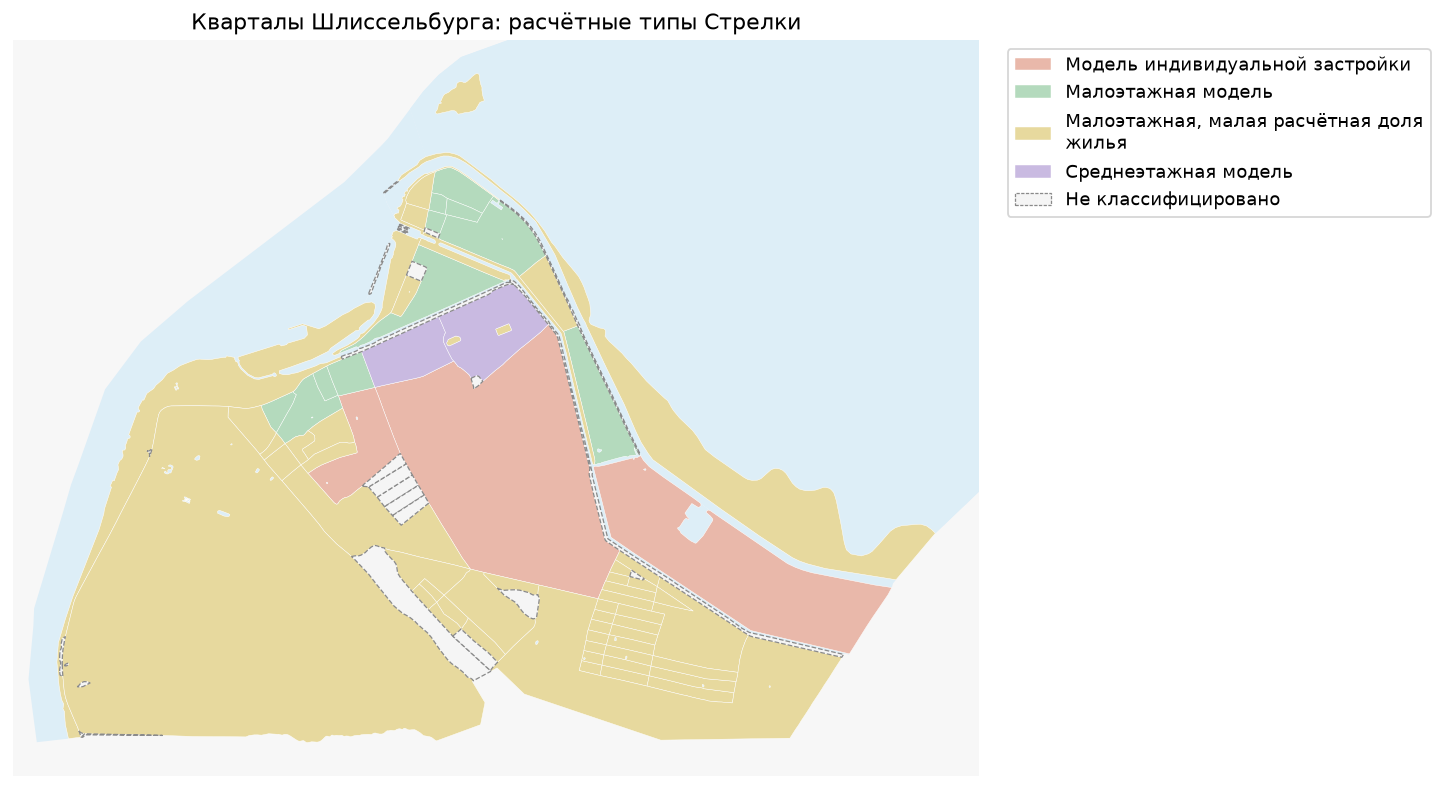

In [9]:
eligible = density.loc[np.isfinite(density[['l','fsi','mxi']]).all(axis=1) & density.fsi.gt(0)].copy()
blocks['spacematrix_cluster'] = pd.Series(pd.NA, index=blocks.index, dtype='Int64')
blocks['spacematrix_morphotype'] = None
blocks['strelka_morphotype'] = None
cluster_count = min(11, len(eligible), len(eligible[['l','fsi','mxi']].drop_duplicates()))
if cluster_count:
    spacematrix, clusters = get_spacematrix_morphotypes(eligible, n_clusters=cluster_count, random_state=RANDOM_STATE)
    strelka = get_strelka_morphotypes(eligible)
    blocks.loc[eligible.index, 'spacematrix_cluster'] = spacematrix['cluster'].astype('Int64')
    blocks.loc[eligible.index, 'spacematrix_morphotype'] = spacematrix['morphotype']
    blocks.loc[eligible.index, 'strelka_morphotype'] = strelka['morphotype']
else:
    clusters = pd.DataFrame(columns=['l','fsi','mxi','morphotype'])
clusters.to_csv(RESULTS/'spacematrix_clusters.csv', index_label='cluster', encoding='utf-8-sig')
save_geojson(blocks, PREPARED/'blocks_metrics.geojson', keep_index=True)
stage('objects', status='saved', buildings=len(buildings), population=float(blocks.population.sum()),
      residential_buildings=int(building_raw.is_living.sum()), unknown_building_yes=int(building_raw.building.eq('yes').sum()),
      floors_estimated=int(floors_estimated.sum()), schools=len(schools), capacity=float(blocks.capacity.sum()),
      school_capacity_estimated=int(schools.capacity_estimated.sum()), school_capacity_source='manual_existing_state',
      buildings_unassigned=len(excess_buildings), schools_unassigned=len(excess_schools),
      spacematrix_clusters=cluster_count, morphotype_eligible=len(eligible))

cluster_view=clusters[['l','fsi','mxi']].rename(columns={'l':'L','fsi':'FSI','mxi':'MXI'})
cluster_view['Расчётный тип']=clusters.morphotype.map(morphotype_title)
display(cluster_view.rename_axis('Кластер'))
type_view=blocks[['spacematrix_cluster','spacematrix_morphotype','strelka_morphotype']].copy()
type_view['spacematrix_morphotype']=type_view.spacematrix_morphotype.map(morphotype_title)
type_view['strelka_morphotype']=type_view.strelka_morphotype.map(morphotype_title)
display_table(type_view.head(12),index_label='Квартал')
display(blocks.strelka_morphotype.map(morphotype_title).value_counts(dropna=False).rename('Кварталов').to_frame())
print(f'Классифицировано {count_text(len(eligible),"квартал","квартала","кварталов")}, кластеров Spacematrix {cluster_count}, разных названий {blocks.spacematrix_morphotype.nunique()}; типов Стрелки {blocks.strelka_morphotype.nunique()}.')
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, field, title in zip(axes, ['population','fsi'], ['Модельное население','FSI: поэтажная площадь / площадь квартала']):
    extra = {'legend_kwds':{'loc':'upper left','bbox_to_anchor':(1.02,1)}} if field=='spacematrix_morphotype' else {}
    blocks.plot(ax=ax, column=field, cmap=MAP_NUMERIC_CMAP, legend=True, edgecolor=MAP_STYLE['blockBoundary'], linewidth=0.2, missing_kwds={'color':MAP_STYLE['missing'],'edgecolor':MAP_STYLE['missingOutline'],'linestyle':'--','linewidth':0.7,'label':'Не классифицировано'}, **extra)
    plot_water_background(ax)
    if blocks[field].isna().any():
        ax.legend(handles=[Patch(facecolor=MAP_STYLE['missing'],edgecolor=MAP_STYLE['missingOutline'],linestyle='--',label='Нет данных')],
            loc='lower left',fontsize=8,framealpha=1,facecolor=MAP_STYLE['ui']['panel'],edgecolor=MAP_STYLE['ui']['grid'])
    ax.set_title(title); ax.set_axis_off()
    if ax.get_legend() is not None:
        for label in ax.get_legend().get_texts(): label.set_text(morphotype_title(label.get_text()))
fig.tight_layout(); fig.savefig(RESULTS/'common_metrics.png', dpi=170, bbox_inches='tight'); plt.show()
fig,ax = plt.subplots(figsize=(11,8))
blocks.plot(ax=ax,column='spacematrix_morphotype',categories=MAP_CATEGORIES['spacematrix_morphotype'],
    cmap=MAP_CATEGORY_CMAPS['spacematrix_morphotype'],legend=True,edgecolor=MAP_STYLE['blockBoundary'],linewidth=0.25,
    missing_kwds={'color':MAP_STYLE['missing'],'edgecolor':MAP_STYLE['missingOutline'],'linestyle':'--','linewidth':0.7,'label':'Не классифицировано'},
    legend_kwds={'loc':'upper left','bbox_to_anchor':(1.02,1),'fontsize':9})
plot_water_background(ax)
ax.set_title('Кварталы Шлиссельбурга: расчётные типы Spacematrix'); ax.set_axis_off()
for label in ax.get_legend().get_texts():
    label.set_text(textwrap.fill(morphotype_title(label.get_text()),width=34))
fig.tight_layout(); fig.savefig(RESULTS/'spacematrix_morphotypes.png',dpi=170,bbox_inches='tight'); plt.show()
fig,ax = plt.subplots(figsize=(11,8))
blocks.plot(ax=ax,column='strelka_morphotype',categories=MAP_CATEGORIES['strelka_morphotype'],
    cmap=MAP_CATEGORY_CMAPS['strelka_morphotype'],legend=True,edgecolor=MAP_STYLE['blockBoundary'],linewidth=0.25,
    missing_kwds={'color':MAP_STYLE['missing'],'edgecolor':MAP_STYLE['missingOutline'],'linestyle':'--','linewidth':0.7,'label':'Не классифицировано'},
    legend_kwds={'loc':'upper left','bbox_to_anchor':(1.02,1)})
plot_water_background(ax)
ax.set_title('Кварталы Шлиссельбурга: расчётные типы Стрелки'); ax.set_axis_off()
for label in ax.get_legend().get_texts(): label.set_text(textwrap.fill(morphotype_title(label.get_text()),width=34))
fig.tight_layout(); fig.savefig(RESULTS/'strelka_morphotypes.png',dpi=170,bbox_inches='tight'); plt.show()

## 8. Время в пути между кварталами

Для расчёта поездок улицы представлены графом, то есть сетью соединённых точек. Узлы обозначают точки соединения участков, например перекрёстки. Связи между узлами обозначают разрешённые перемещения по участкам улиц; для каждой связи известны длина и расчётное время. Поиск пути выбирает последовательность связей с наименьшим суммарным временем.

Пешеходная сеть `walk` и автомобильная `drive` различаются разрешёнными путями и направлениями движения. Пешеход может использовать проход, недоступный автомобилю; автомобильная односторонность учитывается в `drive` и не запрещает обратный пешеходный проход. Поэтому режимы рассчитываются отдельно. Паромы и общественный транспорт в них отсутствуют. Параметры расчёта школьной обеспеченности заданы в разделе 9.

Квартал представлен точкой внутри его контура, которая не обязательно совпадает с геометрическим центром. Для каждого дорожного участка проверяются три возможные точки подключения: ближайшая проекция на его линию и оба конца. Из этих кандидатов выбирается ближайший с прямым соединителем без пересечения внутренности водного контура. Это приближение доступа к сети: видимость всех возможных внутренних точек участка и проходимость через заборы, здания и закрытые дворы не проверяются. Мост учитывается, если соответствующая связь есть в дорожной сети. При отсутствии допустимого соединителя квартал остаётся без подключения.

В расчётной копии графа дорожный участок разделяется в точке подключения; времена его частей пропорциональны длинам. Если на одном участке находятся несколько подключений, они образуют общую последовательность. Обратное движение доступно только при наличии соответствующего направления в исходной сети, а отдельные островные части сохраняются. Временные узлы имеют отрицательные идентификаторы и не входят в сохранённые исходные GraphML.

Скорость ходьбы принята равной **5 км/ч**. Автомобильные скорости определяются настройками IduEdu по типам дорог. Свойство `maxspeed` исходных данных OpenStreetMap (OSM) сохраняется отдельно от принятой скорости. Пробки и поиск парковки отсутствуют. В обоих режимах к времени движения по сети добавлено время подхода от точки квартала к сети и от сети к точке назначения. Подходы рассчитываются при скорости ходьбы 5 км/ч. Таким образом, `drive` включает условные пешие подходы.

Результат записан в матрицу, квадратную таблицу времени с одними и теми же кварталами в строках и столбцах. Строка обозначает квартал отправления, столбец обозначает квартал назначения, ячейка содержит **минуты**. Направление существенно: время автомобильного маршрута в обратном направлении может отличаться. В диагональной ячейке отправление и назначение соответствуют одной и той же расчётной точке квартала, поэтому условно записано **0 минут**, даже если квартал изолирован в расчётной сети. Внутренние перемещения по кварталу модель не рассчитывает. Статус недостижимости и значение `inf` означают, что в выбранной сохранённой сети не найден маршрут или допустимое подключение; это не ноль и не измеренная длительность поездки.

Сеть охватывает муниципальную территорию и дополнительный пояс **2 км**. Дальний объезд вне этой области может отсутствовать; длинная дорога без узла внутри области загрузки также может не попасть в выборку. Отдельные части сети, включая островные, сохраняются. Исходная выборка OSM хранится в XML, текстовом формате объектов и их свойств; рассчитанная сеть хранится в GraphML, формате узлов, связей и их характеристик. Эти файлы позволяют повторять расчёт по той же выборке.

Время рассчитывается между представительными точками кварталов. Например, квартал 3 занимает около **1,957 км²**. Расстояние по прямой между представительными точками школьного корпуса и квартала составляет около **666 м**. Путь до входа в школу отдельно не рассчитывается. Выделение мест жителям своего квартала также не учитывает фактическую длину этого пути.

Матрицы сохранены в `results/matrices/walk.csv` и `drive.csv`, а также в `walk.geojson` и `drive.geojson`. В GeoJSON каждый объект является кварталом отправления; свойство `travel_times_min` содержит время в минутах до всех кварталов назначения по их номерам. `null` означает, что путь не найден. После записи файл повторно читается, номера и все времена сравниваются с рассчитанной матрицей. Следующие расчёты получают именно повторно прочитанные значения.

Пешком: прочитан сохранённый граф, узлов 13 235


Пешком: сеть и подключение кварталов. Таблица показывает связность сети и длины подходов.


,Значение
Источник сети,Сохранённая сеть GraphML
Узлов сети,13235
Дорожных связей,30020
Связных частей без учёта направления,34
Подключено кварталов,96
Кварталов без подключения,1
"Наибольшая длина подхода к сети, м",238.605726
"Медианная длина подхода к сети, м",31.244595
Пар кварталов без пути,754


Кварталы с самыми длинными подходами к сети. Проверка подхода учитывает пересечение воды.


,Подключение,"Длина подхода к сети, м","Время подхода к сети, мин"
Квартал,,,
89,Подключён,238.605726,2.863269
26,Подключён,231.622115,2.779465
71,Подключён,147.912124,1.774945
20,Подключён,137.954036,1.655448
90,Подключён,79.486597,0.953839
10,Подключён,73.947203,0.887366
76,Подключён,63.457358,0.761488
8,Подключён,56.811324,0.681736
18,Подключён,55.754462,0.669054


...

,Значение
Источник сети,Сохранённая сеть GraphML
Узлов сети,3619
Дорожных связей,7065
Связных частей без учёта направления,6
Подключено кварталов,90
Кварталов без подключения,7
"Наибольшая длина подхода к сети, м",629.70348
"Медианная длина подхода к сети, м",39.449137
Пар кварталов без пути,1302


Кварталы с самыми длинными подходами к сети. Проверка подхода учитывает пересечение воды.


,Подключение,"Длина подхода к сети, м","Время подхода к сети, мин"
Квартал,,,
26,Подключён,629.703480,7.556442
3,Подключён,479.685635,5.756228
89,Подключён,344.965922,4.139591
72,Подключён,243.437067,2.921245
77,Подключён,185.549936,2.226599
71,Подключён,181.739707,2.180876
76,Подключён,158.343457,1.900121
65,Подключён,158.137096,1.897645
9,Подключён,157.305192,1.887662


Полная диагностика: results/graph_diagnostics.json; технические поля подключений: results/graph_attachments_drive.csv.
На автомобиле: фрагмент направленной матрицы, минуты; inf означает отсутствие найденного пути.


Квартал назначения,0,1,2,3,93,94,95,96
Квартал отправления,,,,,,,,
0,0.000000,2.281623,1.440742,8.366100,inf,inf,inf,inf
1,2.281623,0.000000,1.883019,10.508016,inf,inf,inf,inf
2,1.440742,1.883019,0.000000,9.667135,inf,inf,inf,inf
3,8.366100,10.508016,9.667135,0.000000,inf,inf,inf,inf
93,inf,inf,inf,inf,0.0,inf,inf,inf
94,inf,inf,inf,inf,inf,0.0,inf,inf
95,inf,inf,inf,inf,inf,inf,0.0,inf
96,inf,inf,inf,inf,inf,inf,inf,0.0


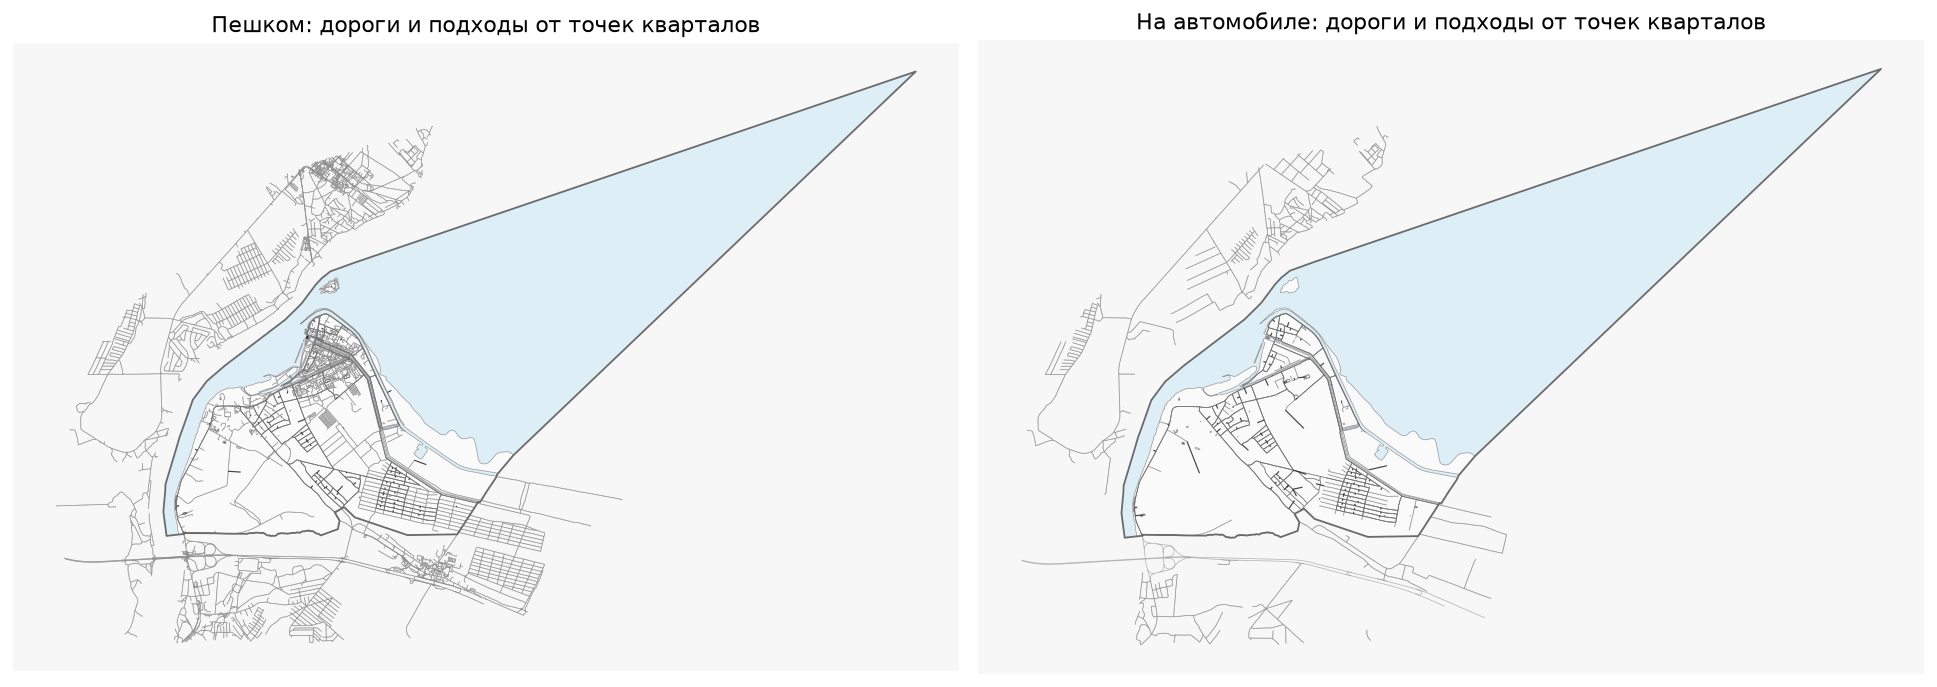

Сохранены сети GraphML и матрицы времени в CSV и GeoJSON. Единицы времени: минуты. Следующие расчёты используют матрицы, повторно прочитанные из GeoJSON.


In [10]:
from iduedu.modules.drive_walk_builder import get_max_speed
from osmnx._overpass import _get_network_filter
import re
import xml.etree.ElementTree as ET
from shapely.ops import substring

GRAPH_BUFFER_M = 2000.0
GRAPH_MODEL_VERSION = 'osmnx-mainmap-xml-all-components-water-connectors-v2'
graph_context_local = boundary.to_crs(local_crs).geometry.union_all().buffer(GRAPH_BUFFER_M)
graph_context = gpd.GeoSeries([graph_context_local], crs=local_crs).to_crs(4326).iloc[0]
save_geojson(gpd.GeoDataFrame({'buffer_m': [GRAPH_BUFFER_M], 'geometry': [graph_context_local]}, crs=local_crs),
             PREPARED / 'graph_context.geojson')

def compile_network_filter(filter_text):
    # Installed OSMnx 2.1.1 uses conjunctions of simple quoted tag clauses.
    pattern = re.compile(r'\["([^"\]]+)"(?:(=|!=|~|!~)"([^"\]]*)")?\]')
    matches = list(pattern.finditer(filter_text))
    if ''.join(match.group(0) for match in matches) != filter_text:
        raise ValueError(f'Неподдерживаемая конструкция фильтра OSMnx: {filter_text}')
    clauses = [match.groups() for match in matches]
    def matches_tags(tags):
        for key, operator, expected in clauses:
            actual = tags.get(key)
            if operator is None and actual is None:
                return False
            if operator == '=' and actual != expected:
                return False
            if operator == '!=' and actual == expected:
                return False
            if operator == '~' and (actual is None or re.search(expected, actual) is None):
                return False
            if operator == '!~' and actual is not None and re.search(expected, actual) is not None:
                return False
        return True
    return matches_tags

def graph_from_snapshot(mode):
    source_root = ET.parse(SNAPSHOT_XML).getroot()
    filter_text = _get_network_filter(mode)
    accepts = compile_network_filter(filter_text)
    source_ways = {int(way.attrib['id']):way for way in source_root.findall('way')}
    selected = [way for way in source_ways.values()
                if accepts({tag.attrib['k']:tag.attrib['v'] for tag in way.findall('tag')})]
    used_nodes = {int(nd.attrib['ref']) for way in selected for nd in way.findall('nd')}
    selected_nodes = [node for node in source_root.findall('node') if int(node.attrib['id']) in used_nodes]
    if len(selected_nodes) != len(used_nodes):
        raise ValueError('Для дорожного графа отсутствуют узлы объектов way из OSM.')
    filtered = ET.Element('osm', version='0.6', generator='LocalCourseStudy')
    for element in [*selected_nodes, *selected]:
        filtered.append(element)
    filtered_xml = PREPARED / f'network_{mode}.osm'
    ET.ElementTree(filtered).write(filtered_xml, encoding='utf-8', xml_declaration=True)
    graph = ox.graph_from_xml(filtered_xml, bidirectional=(mode == 'walk'), retain_all=True, simplify=False)
    graph = ox.truncate.truncate_graph_polygon(graph, graph_context, truncate_by_edge=False)
    graph.graph['study_network_filter'] = filter_text
    graph.graph['study_snapshot_sha256'] = snapshot_metadata['sha256']
    # Compare unfiltered Map API coverage with the separately downloaded municipal road layer.
    road_keys = layers['roads'].get('osm_key', pd.Series(dtype=str)).dropna().astype(str)
    raw_road_ids = {int(key.split('/')[1]) for key in road_keys if key.startswith('way/')}
    missing_ids = sorted(raw_road_ids - set(source_ways))
    coverage = {'raw_municipal_road_ways':len(raw_road_ids), 'snapshot_ways':len(source_ways),
                'missing_raw_road_way_ids':missing_ids, 'mode_filter':filter_text,
                'selected_road_ways_before_context_clip':len(selected)}
    save_json(RESULTS / f'graph_source_coverage_{mode}.json',coverage)
    if missing_ids:
        print(f'{MODE_LABELS[mode]}: в XML не хватает объектов way из исходного слоя дорог: {number_text(len(missing_ids))}. Подробности сохранены в диагностике.',flush=True)
    else:
        print(f'{MODE_LABELS[mode]}: все объекты way исходного муниципального слоя дорог присутствуют в XML: {number_text(len(raw_road_ids))}.',flush=True)
    return graph

def graph_fingerprint(mode):
    payload = {'model': GRAPH_MODEL_VERSION, 'mode': mode, 'polygon': graph_context.wkb_hex,
               'crs': str(local_crs), 'walk_speed_kph': WALK_SPEED_KPH,
               'osmnx': manifest['versions']['osmnx'], 'iduedu': manifest['versions']['iduedu'],
               'snapshot_sha256':snapshot_metadata['sha256'],'network_filter':_get_network_filter(mode)}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode('utf-8')).hexdigest()

def validate_graph(graph):
    if not graph.is_directed() or not graph.is_multigraph():
        raise ValueError('Ожидался ориентированный мультиграф.')
    if graph.number_of_nodes() == 0 or graph.number_of_edges() == 0:
        raise ValueError('Транспортный граф пуст.')
    for _, _, _, attrs in graph.edges(keys=True, data=True):
        for field in ('time_min', 'length_meter', 'speed_kph'):
            value = float(attrs[field])
            if not math.isfinite(value) or value < 0 or (field == 'speed_kph' and value == 0):
                raise ValueError(f'Недопустимое значение {field}: {value}')

def get_mode_graph(mode):
    path = GRAPHS / f'{mode}.graphml'
    signature = graph_fingerprint(mode)
    dtypes = {'time_min': float, 'length_meter': float, 'speed_kph': float,
              'travel_time': float, 'length_osm': float}
    if path.exists() and not REFRESH_DATA:
        cached = ox.load_graphml(path, edge_dtypes=dtypes)
        if cached.graph.get('study_signature') == signature:
            validate_graph(cached)
            print(f'{MODE_LABELS[mode]}: прочитан сохранённый граф, узлов {number_text(len(cached))}', flush=True)
            return cached, 'saved_graphml'
        print(f'{MODE_LABELS[mode]}: параметры сохранённого графа изменились; требуется перестроение.', flush=True)
    print(f'{MODE_LABELS[mode]}: построение сети из сохранённой XML-выборки OpenStreetMap...', flush=True)
    graph = graph_from_snapshot(mode)
    graph = ox.project_graph(graph, to_crs=local_crs)
    for u, v, key, attrs in graph.edges(keys=True, data=True):
        geometry = attrs.get('geometry')
        if geometry is None:
            geometry = LineString([(graph.nodes[u]['x'], graph.nodes[u]['y']),
                                   (graph.nodes[v]['x'], graph.nodes[v]['y'])])
        attrs['geometry'] = geometry
        attrs['length_osm'] = float(attrs['length'])
        attrs['length_meter'] = float(geometry.length)
        if 'maxspeed' in attrs:
            attrs['osm_maxspeed'] = attrs['maxspeed']
        highway = attrs.get('highway', 'road')
        speed_kph = WALK_SPEED_KPH if mode == 'walk' else float(get_max_speed(highway)) * 60 / 1000
        attrs['speed_kph'] = speed_kph
        attrs['time_min'] = attrs['length_meter'] / (speed_kph * 1000 / 60)
        attrs['travel_time'] = attrs['time_min'] * 60
    graph.graph.update(study_signature=signature, study_model=GRAPH_MODEL_VERSION,
                       study_mode=mode, study_buffer_m=GRAPH_BUFFER_M,
                       study_source='OpenStreetMap contributors, ODbL', study_units='time_min: minutes; length_meter: metres')
    validate_graph(graph)
    ox.save_graphml(graph, filepath=path)
    restored = ox.load_graphml(path, edge_dtypes=dtypes)
    validate_graph(restored)
    if set(graph.nodes) != set(restored.nodes) or set(graph.edges(keys=True)) != set(restored.edges(keys=True)):
        raise AssertionError('После сохранения изменился состав графа.')
    for u, v, key, attrs in graph.edges(keys=True, data=True):
        if attrs['time_min'] != restored[u][v][key]['time_min']:
            raise AssertionError('После сохранения изменился вес ребра.')
    print(f'{MODE_LABELS[mode]}: граф сохранён и повторно прочитан, узлов {number_text(len(restored))}', flush=True)
    return restored, 'built_from_snapshot_and_roundtrip_checked'

def edge_snap_catalogue(graph):
    families = {}
    for u, v, key, attrs in graph.edges(keys=True, data=True):
        geometry = attrs.get('geometry')
        if geometry is None:
            geometry = LineString([(graph.nodes[u]['x'], graph.nodes[u]['y']),
                                   (graph.nodes[v]['x'], graph.nodes[v]['y'])])
        if not isinstance(geometry, LineString) or geometry.is_empty:
            raise ValueError(f'Участок {u}, {v}, {key} не имеет линейной геометрии.')
        coordinates = tuple(geometry.coords)
        source = Point(graph.nodes[u]['x'], graph.nodes[u]['y'])
        target = Point(graph.nodes[v]['x'], graph.nodes[v]['y'])
        direct = source.distance(Point(coordinates[0])) + target.distance(Point(coordinates[-1]))
        reverse = source.distance(Point(coordinates[-1])) + target.distance(Point(coordinates[0]))
        if reverse < direct:
            coordinates = coordinates[::-1]
        backwards = coordinates[::-1]
        forward = coordinates <= backwards
        canonical = coordinates if forward else backwards
        source_ids = attrs.get('osmid')
        if source_ids is None:
            source_ids = attrs.get('physical_edge_id')
        if source_ids is None:
            physical_identity = ('key', str(key))
        else:
            source_ids = source_ids if isinstance(source_ids, (list, tuple, set)) else [source_ids]
            physical_identity = ('source', tuple(sorted(str(source_id) for source_id in source_ids)))
        family_key = (min(int(u), int(v)), max(int(u), int(v)), physical_identity, canonical)
        if family_key not in families:
            families[family_key] = {
                'geometry': LineString(canonical),
                'start_node': int(u) if forward else int(v),
                'end_node': int(v) if forward else int(u),
                'edges': [], 'snap_nodes': {},
            }
        families[family_key]['edges'].append({
            'u': int(u), 'v': int(v), 'key': key, 'forward': forward, 'attrs': dict(attrs),
        })
    if not families:
        raise ValueError('Для привязки кварталов нет дорожных участков.')
    return list(families.values())

def split_snap_edges(graph, families):
    routing_graph = graph.copy()
    for family in families:
        geometry = family['geometry']
        length = float(geometry.length)
        interior = sorted(family['snap_nodes'].items())
        if not interior:
            continue
        for position, node_id in interior:
            point = geometry.interpolate(position)
            routing_graph.add_node(node_id, x=point.x, y=point.y, virtual_snap=True)
        chain = [(0.0, family['start_node']), *interior, (length, family['end_node'])]
        # Все точки одного участка разрезают каждое его направление одной цепочкой.
        for edge in family['edges']:
            u, v, key = edge['u'], edge['v'], edge['key']
            directed_chain = chain if edge['forward'] else chain[::-1]
            routing_graph.remove_edge(u, v, key)
            for (start, start_node), (end, end_node) in zip(directed_chain[:-1], directed_chain[1:]):
                fraction = abs(end - start) / length
                attrs = dict(edge['attrs'])
                attrs['geometry'] = substring(geometry, start, end)
                attrs['length_meter'] = abs(end - start)
                attrs['time_min'] = float(edge['attrs']['time_min']) * fraction
                attrs['travel_time'] = attrs['time_min'] * 60
                for field in ('length', 'length_osm'):
                    if field in attrs:
                        attrs[field] = float(edge['attrs'][field]) * fraction
                routing_graph.add_edge(start_node, end_node, key=key, **attrs)
    return routing_graph

def attach_blocks(graph, mode):
    families = edge_snap_catalogue(graph)
    geometries = np.array([family['geometry'] for family in families], dtype=object)
    next_virtual_node = min([0, *(int(node) for node in graph.nodes)]) - 1
    points = blocks.geometry.representative_point()
    records, connector_records = [], []
    water = WATER_POLYGONS
    for block_id, point in points.items():
        distances = shapely.distance(geometries, point)
        # Просматриваются все участки без ограничения радиуса или числа кандидатов.
        ordered = np.argsort(distances, kind='stable')
        selected, rejected, best_distance = None, 0, np.inf
        for position in ordered:
            if float(distances[int(position)]) > best_distance:
                break
            family = families[int(position)]
            geometry = family['geometry']
            length = float(geometry.length)
            projection = float(geometry.project(point)) if length > 0 else 0.0
            # Концы сохраняют возможность подхода при закрытой водой проекции.
            for candidate_position in dict.fromkeys((projection, 0.0, length)):
                target = geometry.interpolate(candidate_position) if length > 0 else Point(geometry.coords[0])
                distance_m = float(point.distance(target))
                if distance_m >= best_distance:
                    continue
                connector = LineString([point, target])
                intersects_water = (not water.is_empty and
                                    (water.contains(point) if point.equals(target)
                                     else connector.relate_pattern(water, 'T********')))
                if intersects_water:
                    rejected += 1
                    continue
                best_distance = distance_m
                selected = (family, target, connector, distance_m, candidate_position)
        if selected is None:
            records.append({'block_id': int(block_id), 'node_id': None, 'status': 'no_water_safe_edge',
                            'connector_m': np.nan, 'connector_min': np.nan, 'rejected_over_water': rejected,
                            'point_x': point.x, 'point_y': point.y})
            continue
        family, target, connector, distance_m, projection = selected
        if projection == 0.0:
            node_id = family['start_node']
        elif projection == family['geometry'].length:
            node_id = family['end_node']
        else:
            if projection not in family['snap_nodes']:
                family['snap_nodes'][projection] = next_virtual_node
                next_virtual_node -= 1
            node_id = family['snap_nodes'][projection]
        edge = family['edges'][0]
        edge_projection = projection if edge['forward'] else family['geometry'].length - projection
        records.append({'block_id': int(block_id), 'node_id': node_id, 'status': 'attached',
                        'connector_m': distance_m, 'connector_min': distance_m / (WALK_SPEED_KPH * 1000 / 60),
                        'rejected_over_water': rejected, 'point_x': point.x, 'point_y': point.y,
                        'edge_u': edge['u'], 'edge_v': edge['v'], 'edge_key': edge['key'],
                        'edge_position_m': edge_projection, 'snap_x': target.x, 'snap_y': target.y})
        connector_records.append({'block_id': int(block_id), 'node_id': str(node_id),
                                  'length_m': distance_m,
                                  'geometry': connector if distance_m > 0 else point})
    attachment_columns = ['node_id', 'status', 'connector_m', 'connector_min', 'rejected_over_water',
                          'point_x', 'point_y', 'edge_u', 'edge_v', 'edge_key', 'edge_position_m', 'snap_x', 'snap_y']
    attachment = pd.DataFrame(records).set_index('block_id').reindex(index=blocks.index, columns=attachment_columns)
    for field in ('node_id', 'edge_u', 'edge_v'):
        if field not in attachment:
            attachment[field] = pd.NA
        attachment[field] = pd.array(attachment[field], dtype='Int64')
    routing_graph = split_snap_edges(graph, families)
    attached_nodes = attachment.loc[attachment['status'].eq('attached'), 'node_id'].astype(int)
    if not all(node in routing_graph for node in attached_nodes):
        raise AssertionError('Точка привязки отсутствует в расчётной дорожной сети.')
    attachment.to_csv(RESULTS / f'graph_attachments_{mode}.csv', index_label='block_id')
    connectors = (gpd.GeoDataFrame(connector_records, geometry='geometry', crs=local_crs)
                  if connector_records else gpd.GeoDataFrame({'geometry': []}, geometry='geometry', crs=local_crs))
    save_geojson(connectors, RESULTS / f'graph_connectors_{mode}.geojson')
    return attachment, connectors, routing_graph

def calculate_full_matrix(graph, attachment):
    block_ids = blocks.index.to_numpy(dtype=int)
    matrix = pd.DataFrame(np.inf, index=block_ids, columns=block_ids)
    attached = attachment.loc[attachment['status'].eq('attached')]
    node_to_blocks = {}
    for block_id, row in attached.iterrows():
        node_to_blocks.setdefault(int(row['node_id']), []).append(int(block_id))
    for number, (source_node, source_blocks) in enumerate(node_to_blocks.items(), start=1):
        shortest = nx.single_source_dijkstra_path_length(graph, source_node, weight='time_min')
        for target_node, target_blocks in node_to_blocks.items():
            if target_node not in shortest:
                continue
            for source_block in source_blocks:
                origin_time = float(attachment.at[source_block, 'connector_min'])
                for target_block in target_blocks:
                    destination_time = float(attachment.at[target_block, 'connector_min'])
                    matrix.at[source_block, target_block] = shortest[target_node] + origin_time + destination_time
    np.fill_diagonal(matrix.values, 0.0)
    if (matrix.to_numpy() < 0).any() or np.isnan(matrix.to_numpy()).any():
        raise AssertionError('Матрица содержит отрицательные или неизвестные значения.')
    if not np.array_equal(matrix.index, blocks.index) or not np.array_equal(matrix.columns, blocks.index):
        raise AssertionError('Идентификаторы кварталов и матрицы не совпадают.')
    return matrix

graphs, matrices, graph_attachments, graph_connectors = {}, {}, {}, {}
graph_diagnostics = {}
for mode in ('walk', 'drive'):
    graph, source_status = get_mode_graph(mode)
    attachment, connectors, routing_graph = attach_blocks(graph, mode)
    matrix = calculate_full_matrix(routing_graph, attachment)
    matrix.to_csv(MATRICES / f'{mode}.csv', index_label='block_id')
    # Read the actual CSV back: inf must remain unreachable, identifiers must survive.
    restored_matrix = pd.read_csv(MATRICES / f'{mode}.csv', index_col='block_id')
    restored_matrix.index = restored_matrix.index.astype(int)
    restored_matrix.columns = restored_matrix.columns.astype(int)
    if not np.array_equal(matrix.to_numpy(), restored_matrix.to_numpy()):
        if not np.allclose(matrix.to_numpy(), restored_matrix.to_numpy(), rtol=1e-14, atol=1e-14, equal_nan=False):
            raise AssertionError('Матрица после чтения CSV отличается от расчёта.')
    spatial_matrix=blocks[['geometry']].copy()
    spatial_matrix['block_id']=blocks.index.astype(int)
    spatial_matrix['travel_times_min']=[
        {str(int(target)):clean_value(value) for target,value in matrix.loc[origin].items()}
        for origin in blocks.index
    ]
    spatial_matrix_path=MATRICES/f'{mode}.geojson'
    save_geojson(spatial_matrix,spatial_matrix_path)
    spatial_payload=json.loads(spatial_matrix_path.read_text(encoding='utf-8'))
    spatial_payload.update({'source':'OpenStreetMap contributors, ODbL','mode':mode,
        'time_unit':'min','unreachable_value':None,
        'description':'Время между точками кварталов; null означает отсутствие найденного пути.'})
    save_json(spatial_matrix_path,spatial_payload)
    spatial_payload=json.loads(spatial_matrix_path.read_text(encoding='utf-8'))
    restored_rows={}
    for feature in spatial_payload['features']:
        properties=feature['properties']
        origin=int(properties['block_id'])
        if origin in restored_rows:
            raise AssertionError('Повтор квартала в GeoJSON матрицы времени.')
        restored_rows[origin]={int(target):np.inf if value is None else float(value)
            for target,value in properties['travel_times_min'].items()}
    restored_geojson_matrix=pd.DataFrame.from_dict(restored_rows,orient='index').reindex(index=blocks.index,columns=blocks.index)
    if not np.array_equal(restored_geojson_matrix.to_numpy(),matrix.to_numpy()):
        raise AssertionError('Матрица после чтения GeoJSON отличается от расчёта.')
    weak_components = list(nx.weakly_connected_components(graph))
    diagnostic = {'source_status': source_status, 'nodes': graph.number_of_nodes(),
                  'edges': graph.number_of_edges(), 'weak_components': len(weak_components),
                  'strong_components': nx.number_strongly_connected_components(graph),
                  'largest_weak_component_nodes': max(map(len, weak_components)),
                  'attached_blocks': int(attachment['status'].eq('attached').sum()),
                  'unattached_blocks': int(attachment['status'].ne('attached').sum()),
                  'max_connector_m': attachment['connector_m'].max(),
                  'median_connector_m': attachment['connector_m'].median(),
                  'rejected_water_connectors': int(attachment['rejected_over_water'].sum()),
                  'finite_pairs_including_diagonal': int(np.isfinite(matrix.to_numpy()).sum()),
                  'unreachable_pairs': int(np.isinf(matrix.to_numpy()).sum()),
                  'buffer_m': GRAPH_BUFFER_M, 'units': 'minutes',
                  'unreachable_meaning': 'Нет пути в сохранённом графе либо нет допустимого соединителя; дальний объезд вне графа не исключён.'}
    stage('graph_' + mode, **diagnostic)
    graphs[mode], matrices[mode] = graph, restored_geojson_matrix
    graph_attachments[mode], graph_connectors[mode] = attachment, connectors
    graph_diagnostics[mode] = diagnostic
    print(f'{MODE_LABELS[mode]}: сеть и подключение кварталов. Таблица показывает связность сети и длины подходов.')
    diagnostic_view = pd.Series({
        'Источник сети':{'saved_graphml':'Сохранённая сеть GraphML',
            'built_from_snapshot_and_roundtrip_checked':'Построена из XML, проверена после записи'}[source_status],
        'Узлов сети':diagnostic['nodes'], 'Дорожных связей':diagnostic['edges'],
        'Связных частей без учёта направления':diagnostic['weak_components'],
        'Подключено кварталов':diagnostic['attached_blocks'],
        'Кварталов без подключения':diagnostic['unattached_blocks'],
        'Наибольшая длина подхода к сети, м':diagnostic['max_connector_m'],
        'Медианная длина подхода к сети, м':diagnostic['median_connector_m'],
        'Пар кварталов без пути':diagnostic['unreachable_pairs']
    },name='Значение')
    display(diagnostic_view.to_frame())
    print('Кварталы с самыми длинными подходами к сети. Проверка подхода учитывает пересечение воды.')
    attachment_view=attachment.sort_values('connector_m',ascending=False).head(10)[['status','connector_m','connector_min']].copy()
    attachment_view['status']=attachment_view['status'].map({'attached':'Подключён','no_water_safe_edge':'Нет подхода без пересечения воды'})
    display_table(attachment_view,labels={'status':'Подключение','connector_m':'Длина подхода к сети, м',
        'connector_min':'Время подхода к сети, мин'},index_label='Квартал')
    print(f'Полная диагностика: results/graph_diagnostics.json; технические поля подключений: results/graph_attachments_{mode}.csv.')
    matrix_sample = list(dict.fromkeys(list(blocks.index[:4])+list(blocks.index[-4:])))
    print(f'{MODE_LABELS[mode]}: фрагмент направленной матрицы, минуты; inf означает отсутствие найденного пути.')
    display(matrix.loc[matrix_sample,matrix_sample].rename_axis(index='Квартал отправления',columns='Квартал назначения'))

save_json(RESULTS / 'graph_diagnostics.json', graph_diagnostics)
previous_attachment_assumption = 'Время подхода от представительной точки квартала к допустимому узлу добавлено со скоростью 5 км/ч в обоих сценариях.'
edge_attachment_assumption = 'Для подхода к дороге проверяются проекция на участок и его концы. Ближайший кандидат без пересечения воды соединяется с точкой квартала. В обоих режимах время движения по соединителю рассчитывается при скорости ходьбы 5 км/ч.'
manifest['assumptions'] = [edge_attachment_assumption if text == previous_attachment_assumption else text
                           for text in manifest['assumptions']]
for text in [
    'Графы охватывают муниципальную территорию с поясом 2 км; дальние объезды за пределами сохранённого графа могут отсутствовать.',
    edge_attachment_assumption
]:
    if text not in manifest['assumptions']:
        manifest['assumptions'].append(text)
for text in [
    'Прямой соединитель к сети проверяется только на пересечение водных полигонов OSM и не подтверждает проходимость через заборы, здания и закрытые территории.',
    'Неизвестные или неполные водные полигоны OSM могут влиять на проверку подхода к сети; длины соединителей сохранены для контроля.'
]:
    if text not in manifest['limitations']:
        manifest['limitations'].append(text)
save_json(manifest_path, manifest)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, mode in zip(axes, ('walk', 'drive')):
    edges = ox.graph_to_gdfs(graphs[mode], nodes=False)
    edges.plot(ax=ax, color=MAP_STYLE['roadMajor'], linewidth=0.4, alpha=0.65)
    blocks.plot(ax=ax, color=MAP_STYLE['land'], edgecolor='none', zorder=0.5)
    blocks.boundary.plot(ax=ax, color=MAP_STYLE['boundary'], linewidth=0.4, alpha=0.65)
    if not graph_connectors[mode].empty:
        graph_connectors[mode].plot(ax=ax, color=MAP_STYLE['selection'], linewidth=0.65, alpha=0.8)
    boundary.to_crs(local_crs).boundary.plot(ax=ax, color=MAP_STYLE['boundary'], linewidth=1)
    plot_water_background(ax)
    ax.set_title(f'{MODE_LABELS[mode]}: дороги и подходы от точек кварталов')
    ax.set_aspect('equal')
    ax.set_axis_off()
plt.tight_layout()
plt.show()
print('Сохранены сети GraphML и матрицы времени в CSV и GeoJSON. Единицы времени: минуты. Следующие расчёты используют матрицы, повторно прочитанные из GeoJSON.')

## 9. Распределение школьных мест

Модель распределяет школьные места между кварталами, учитывая потребность жителей, вместимость школ и время в пути. Расчётная потребность в школьных местах для квартала i определяется по формуле `D_i = ceil(N_i × 120 / 1000)`. Здесь `N_i` обозначает модельное население квартала из поля `population`, а `ceil` округляет результат вверх. Число 120 задаёт расчётный параметр в местах на 1000 жителей. Нормативные показатели приведены отдельно ниже.

Потребность рассчитана для всех 97 кварталов. В 16 кварталах она положительна, в 81 равна нулю. Нулевой результат относится к модельной оценке населения по данным OSM и не подтверждает фактическое отсутствие жителей.

Параметр 120 и порог **15 минут** взяты из настройки `school` установленной версии BlocksNet. Для дополнительного сравнения тот же порог отдельно применяется к автомобильной матрице времени. Применение этого порога не является проверкой нормативной территориальной доступности. В обоих режимах используются одинаковые кварталы, население и места.

**Нормативные показатели для сопоставления.** [Местные нормативы градостроительного проектирования (постановление Правительства Ленинградской области от 04.12.2017 № 525), п. 2.1.2](https://arch.lenobl.ru/media/uploads/userfiles/2025/08/27/%D0%9C%D0%9D%D0%93%D0%9F.docx) для городских населённых пунктов зон Б и В устанавливают минимум 91 ученическое место на 1000 человек постоянного населения и максимальную территориальную доступность 500 м. Отнесение Шлиссельбургского городского поселения к зоне Б установлено приложением 3 [Региональных нормативов градостроительного проектирования (постановление Правительства Ленинградской области от 22.03.2012 № 83)](https://arch.lenobl.ru/media/uploads/userfiles/2025/08/27/%D0%A0%D0%9D%D0%93%D0%9F.docx). Примечание к п. 2.1.2 названных Местных нормативов исключает специализированные общеобразовательные организации из указанного радиуса обслуживания; правовой статус конкретных корпусов в этой работе не устанавливался. Нормативное расстояние 500 м не переводилось в минуты и не использовалось вместо модельного порога 15 минут. Нормативный показатель отнесён к постоянному населению; модель использует оценку числа жителей по площади зданий. Модельный расчёт не является проверкой соблюдения нормативов.

Сначала при `self_supply=True` выделяются **места для жителей своего квартала**: `S = min(D, C)`, меньшая из величин потребности D и вместимости C. Матрица времени на этом шаге не используется. Затем оставшаяся потребность обеспечивается свободными местами других кварталов; места распределяются целыми количествами. Алгоритм учитывает время, оставшуюся потребность и вместимость; это не простое назначение ближайшей школы и не чистая минимизация времени.

Полный словарь результата `competitive_provision` приведён ниже. «У жителей» означает квартал, для которого рассчитана потребность в местах, «у назначения» означает квартал расположения мест. В итоговой таблице названия начинаются с `walk_` или `drive_`.

| Поле | Смысл | Единица | Направление |
|---|---|---|---|
| `demand` | Расчётная потребность в школьных местах D | мест | у жителей |
| `demand_within` | Выделенные жителям места в пределах порога, включая S | мест | у жителей |
| `demand_without` | Выделенные жителям места за пределами порога | мест | у жителей |
| `demand_left` | Необеспечённая потребность в местах | мест | у жителей |
| `capacity` | Исходная вместимость C | мест | у назначения |
| `capacity_within` | Места, выделенные распределением в пределах порога, без S | мест | у назначения |
| `capacity_without` | Места, выделенные за пределами порога | мест | у назначения |
| `capacity_left` | Свободные места после распределения | мест | у назначения |
| `provision_strong` | `demand_within / demand` | доля 0..1 | у жителей |
| `provision_weak` | `(demand_within + demand_without) / demand` | доля 0..1 | у жителей |

При `max_depth=1` выполняется один этап с пределом 15 минут включительно. Распределения дальше порога нет: оба поля `without` равны нулю, а `strong` и `weak` совпадают. При нулевой потребности в местах обе доли неопределены. Для каждого квартала действуют балансы:

```text
D = demand_within + demand_without + demand_left
C = S + capacity_within + capacity_without + capacity_left
```

Отдельное S во второй формуле необходимо: библиотека вычитает места для жителей своего квартала из свободной вместимости, но не записывает их в `capacity_within`. Использованные места равны `capacity - capacity_left`.

Итоги обоих режимов и межквартальные связи показаны ниже. Проценты характеризуют условный расчёт, а не фактическую долю зачисленных учеников. Покрытая доля потребности в сводке, `provision_strong_weighted`, равна сумме `demand_within`, делённой на сумму `demand`. Это доля общей расчётной потребности, обеспеченная местами в пределах порога, от 0 до 1.

Каждая строка межквартального распределения содержит `source`, номер квартала жителей, `target`, номер квартала школьного корпуса, и `value`, количество выделенных мест. Например, строка `20 → 3` со значением `value = 2` означает, что модель выделила жителям квартала 20 два места в корпусе квартала 3.

В таблицу включены только строки с разными номерами `source` и `target`. Если жителям квартала 3 выделены места в корпусе квартала 3, эти места учтены при расчёте обеспеченности квартала 3, но отдельной строки `3 → 3` в таблице межквартального распределения нет.

## 10. Среднее время с учётом площади

Показатель `area_accessibility` рассчитывается отдельно для каждого исходного квартала по временам до всех 97 кварталов. В строку входит и сам исходный квартал со временем 0 минут. Группы Spacematrix и расположение школ в этом усреднении не используются. Единица измерения: минуты. Для квартала i он равен `A_i = sum(T_ij × S_j) / sum(S_j)`, где `T_ij` обозначает время до квартала j, а `S_j` обозначает его площадь. Для расчёта нужны матрица времени и площади кварталов. Больший квартал имеет больший вес. Это среднее время до представительных точек с весами площади, а не среднее время поездки реальных жителей.

В текущей пешеходной сети с основной частью города не связаны кварталы 90, 91, 95 и 96. Кварталы 90, 91 и 96 подключены к отдельным компонентам с пешеходными дорожками; для квартала 95 не найден подход к сети без пересечения воды. В автомобильной сети нет допустимого подключения кварталов с 90 по 96. Квартал 96 соответствует Орешку; водный транспорт не включён. Эти результаты характеризуют связность загруженной сети OSM при принятых правилах подключения и не доказывают физическую изоляцию остальных участков.

Поэтому в каждой строке матрицы есть хотя бы одно недостижимое назначение, и среднее время до всех кварталов равно `inf`. Конечные времена между достижимыми парами кварталов сохраняются в матрице. Причины подключения или отказа записаны в `results/graph_attachments_walk.csv` и `results/graph_attachments_drive.csv`.

В GeoJSON бесконечность записана как `null`, поскольку этот формат не поддерживает бесконечные числа. Вспомогательное поле `area_accessibility_status=unreachable` отличает такой результат от отсутствующих исходных данных. В таблицах и на интерактивной странице знак ∞ показан только при этом статусе; пропуск без него означает «нет данных». Название показателя начинается с `walk_` или `drive_` в зависимости от режима.

Пешком: потребность в местах и их распределение по кварталам с модельным населением или школами.


,Потребность в местах,"Вместимость, мест",Необеспечённая потребность в местах,"Выделено жителям в пределах порога, мест","Выделено жителям за пределами порога, мест",Свободные места после распределения,"Выделено другим кварталам в пределах порога, мест","Выделено другим кварталам за пределами порога, мест","Обеспеченность в пределах порога, доля","Обеспеченность с учётом дальних поездок, доля"
Квартал,,,,,,,,,,
3,56,934,0,56,0,876,2,0,1.000000,1.000000
15,398,0,398,0,0,0,0,0,0.000000,0.000000
16,2,0,2,0,0,0,0,0,0.000000,0.000000
17,8,0,8,0,0,0,0,0,0.000000,0.000000
18,1,0,1,0,0,0,0,0,0.000000,0.000000
19,20,0,20,0,0,0,0,0,0.000000,0.000000
20,2,0,0,2,0,0,0,0,1.000000,1.000000
23,626,0,359,267,0,0,0,0,0.426518,0.426518
24,416,683,0,416,0,0,267,0,1.000000,1.000000


,"Среднее время до всех кварталов, мин"
Квартал,
0,∞
1,∞
2,∞
3,∞
4,∞
92,∞
93,∞
94,∞
95,∞


Знак ∞ означает недостижимое назначение; «нет данных» означает пропуск без статуса недостижимости.
На автомобиле: потребность в местах и их распределение по кварталам с модельным населением или школами.


,Потребность в местах,"Вместимость, мест",Необеспечённая потребность в местах,"Выделено жителям в пределах порога, мест","Выделено жителям за пределами порога, мест",Свободные места после распределения,"Выделено другим кварталам в пределах порога, мест","Выделено другим кварталам за пределами порога, мест","Обеспеченность в пределах порога, доля","Обеспеченность с учётом дальних поездок, доля"
Квартал,,,,,,,,,,
3,56,934,0,56,0,0,878,0,1.000000,1.000000
15,398,0,0,398,0,0,0,0,1.000000,1.000000
16,2,0,2,0,0,0,0,0,0.000000,0.000000
17,8,0,8,0,0,0,0,0,0.000000,0.000000
18,1,0,1,0,0,0,0,0,0.000000,0.000000
19,20,0,20,0,0,0,0,0,0.000000,0.000000
20,2,0,2,0,0,0,0,0,0.000000,0.000000
23,626,0,0,626,0,0,0,0,1.000000,1.000000
24,416,683,0,416,0,0,267,0,1.000000,1.000000


,"Среднее время до всех кварталов, мин"
Квартал,
0,∞
1,∞
2,∞
3,∞
4,∞
92,∞
93,∞
94,∞
95,∞


Знак ∞ означает недостижимое назначение; «нет данных» означает пропуск без статуса недостижимости.


,Потребность в местах,"Вместимость, мест","Выделено жителям в пределах порога, мест",Необеспечённая потребность в местах,"Покрытая доля потребности, 0..1","Пар кварталов с путём, включая диагональ",Всего пар кварталов,Кварталов без конечного среднего времени
Передвижение,,,,,,,,
Пешком,1886.0,1617.0,741.0,1145.0,0.392895,8655.0,9409.0,97.0
На автомобиле,1886.0,1617.0,1617.0,269.0,0.857370,8107.0,9409.0,97.0


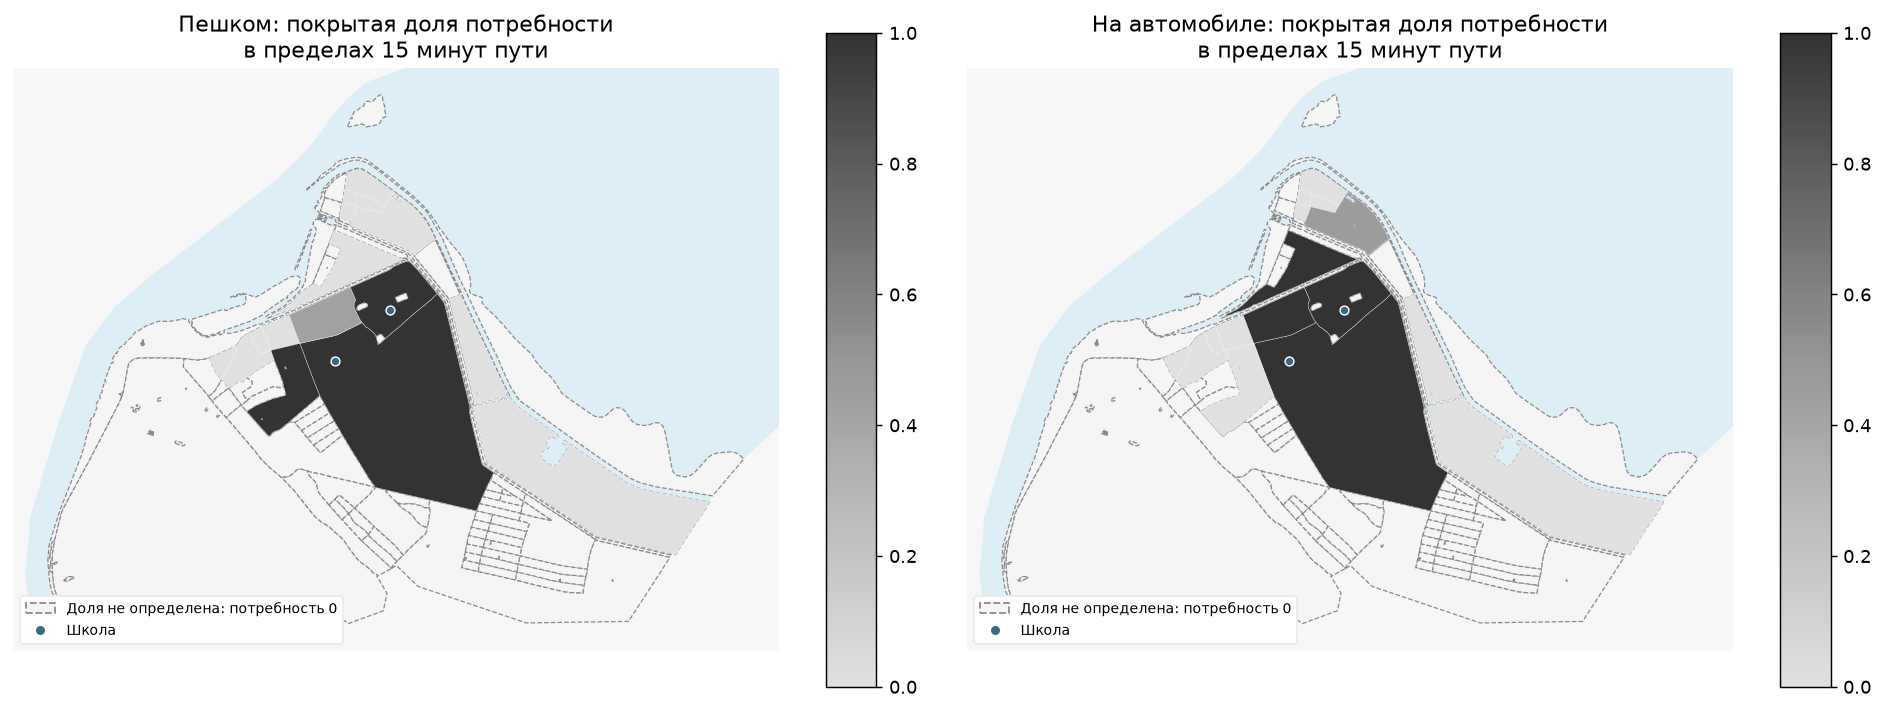

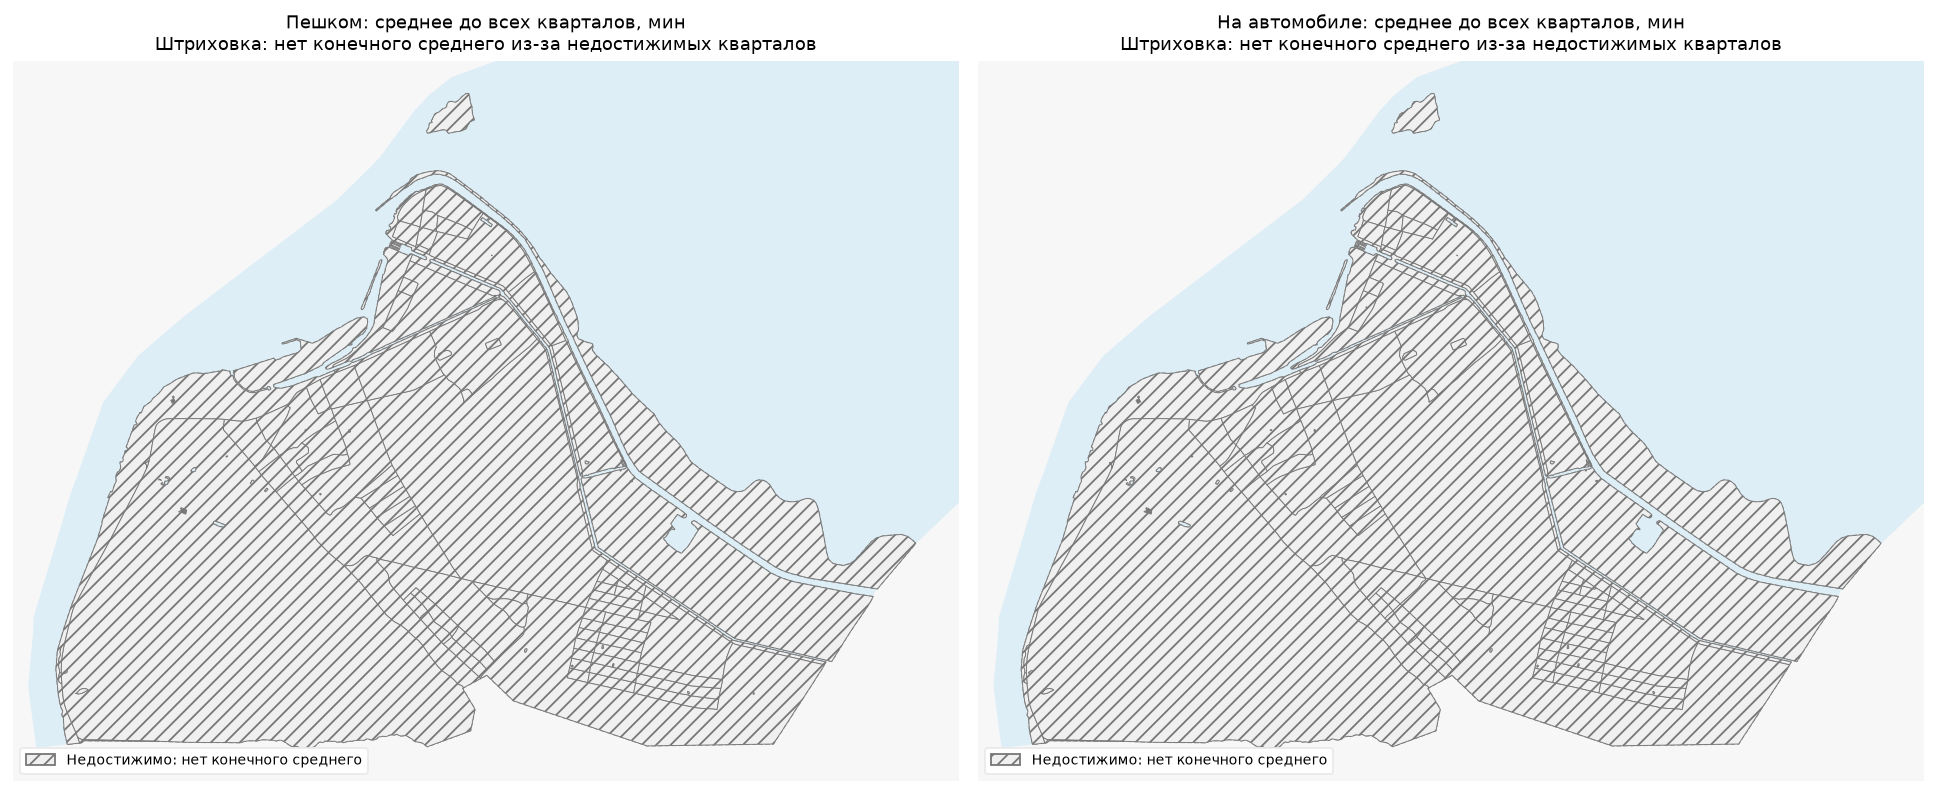

In [11]:
from blocksnet.config import service_types_config
from blocksnet.analysis.provision import competitive_provision
from blocksnet.analysis.network.accessibility import area_accessibility
configure_notebook_logging()

school_config = service_types_config['school']
SCHOOL_DEMAND = int(school_config['demand'])
SCHOOL_THRESHOLD_MIN = int(school_config['accessibility'])
provision_fields = ['demand','capacity','demand_left','demand_within','demand_without',
    'capacity_left','capacity_within','capacity_without','provision_strong','provision_weak']
mode_summaries = {}
provision_links = {}
for mode in ['walk','drive']:
    matrix = matrices[mode]
    assert matrix.index.equals(blocks.index) and matrix.columns.equals(blocks.index)
    assert not matrix.isna().any().any()
    assert np.all(matrix.to_numpy() >= 0) and np.allclose(np.diag(matrix), 0)
    provision, links = competitive_provision(blocks[['population','capacity']], matrix,
        accessibility=SCHOOL_THRESHOLD_MIN, demand=SCHOOL_DEMAND, self_supply=True, max_depth=1)
    for field in provision_fields:
        blocks[f'{mode}_{field}'] = provision[field]
    assert np.allclose(provision.demand, provision.demand_left+provision.demand_within+provision.demand_without)
    for field in ['provision_strong','provision_weak']:
        assert provision[field].dropna().between(0,1).all()
    aa = area_accessibility(matrix, blocks[['site_area']])['area_accessibility']
    finite = np.isfinite(matrix.to_numpy())
    blocks[f'{mode}_area_accessibility'] = aa.replace([np.inf,-np.inf],np.nan)
    blocks[f'{mode}_area_accessibility_status'] = np.where(np.isfinite(aa),'ok','unreachable')
    link_table = links.reset_index()
    link_geometries = [LineString([blocks.geometry.loc[int(s)].representative_point(), blocks.geometry.loc[int(t)].representative_point()])
                       for s,t in zip(link_table.source,link_table.target)]
    link_gdf = gpd.GeoDataFrame(link_table, geometry=link_geometries, crs=CRS)
    provision_links[mode] = link_gdf
    save_geojson(link_gdf, RESULTS/f'provision_links_{mode}.geojson')
    provision.to_csv(RESULTS/f'provision_{mode}.csv', index_label='block_id', encoding='utf-8-sig')
    demand_total = float(provision.demand.sum())
    served_total = float(provision.demand_within.sum())
    mode_summaries[mode] = {
        'demand':demand_total, 'capacity':float(provision.capacity.sum()),
        'demand_within':served_total, 'demand_left':float(provision.demand_left.sum()),
        'provision_strong_weighted':served_total/demand_total if demand_total else None,
        'reachable_pairs':int(finite.sum()),'total_pairs':int(finite.size),
        'area_accessibility_unreachable':int((~np.isfinite(aa)).sum())
    }
    stage('metrics_'+mode,status='saved', **mode_summaries[mode])
    print(f'{MODE_LABELS[mode]}: потребность в местах и их распределение по кварталам с модельным населением или школами.')
    with pd.option_context('display.max_columns',None):
        display_table(provision.loc[(provision.demand>0)|(provision.capacity>0),provision_fields],index_label='Квартал')
        accessibility_columns = [f'{mode}_area_accessibility']
        accessibility_sample = list(dict.fromkeys(list(blocks.index[:5])+list(blocks.index[-5:])))
        accessibility_view=blocks.loc[accessibility_sample,accessibility_columns].copy()
        accessibility_view[accessibility_columns[0]]=[
            accessibility_text(blocks.at[block_id,accessibility_columns[0]],
                blocks.at[block_id,f'{mode}_area_accessibility_status'])
            for block_id in accessibility_sample]
        display_table(accessibility_view,labels={accessibility_columns[0]:'Среднее время до всех кварталов, мин'},index_label='Квартал')
        print('Знак ∞ означает недостижимое назначение; «нет данных» означает пропуск без статуса недостижимости.')
manifest['school_parameters'] = {'demand_per_1000':SCHOOL_DEMAND,'threshold_min':SCHOOL_THRESHOLD_MIN,
    'self_supply':True,'max_depth':1,'source':'blocksnet.config.service_types_config school, installed 1.0.0a9'}
manifest['summary'] = {'blocks':len(blocks),'site_area_km2':float(blocks.site_area.sum()/1e6),
    'buildings':int(blocks.building_count.sum()),'population':float(blocks.population.sum()),
    'schools':int(blocks.school_count.sum()),'capacity':float(blocks.capacity.sum()),'modes':mode_summaries}
save_geojson(blocks, RESULTS/'blocks.geojson', keep_index=True)
blocks.drop(columns='geometry').rename_axis('block_id').to_csv(RESULTS/'blocks.csv', encoding='utf-8-sig')
save_json(manifest_path, manifest)
summary_view=pd.DataFrame(mode_summaries).T.rename(index=MODE_LABELS)
display_table(summary_view,index_label='Передвижение')
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1,2,figsize=(15,8))
for ax,mode,title in zip(axes,['walk','drive'],['Пешком','На автомобиле']):
    blocks.plot(ax=ax, color=MAP_STYLE['missing'], edgecolor=MAP_STYLE['missingOutline'], linewidth=0.7, linestyle='--')
    blocks.loc[blocks[f'{mode}_demand']>0].plot(ax=ax,column=f'{mode}_provision_strong',cmap=MAP_NUMERIC_CMAP,vmin=0,vmax=1,legend=True,edgecolor=MAP_STYLE['blockBoundary'],linewidth=0.2,
        missing_kwds={'color':MAP_STYLE['missing'],'edgecolor':MAP_STYLE['missingOutline'],'linestyle':'--','linewidth':0.7})
    plot_water_background(ax)
    provision_legend = []
    if blocks[f'{mode}_demand'].eq(0).any():
        provision_legend.append(Patch(facecolor=MAP_STYLE['missing'],edgecolor=MAP_STYLE['missingOutline'],linestyle='--',label='Доля не определена: потребность 0'))
    if blocks[f'{mode}_demand'].isna().any() or blocks.loc[blocks[f'{mode}_demand']>0,f'{mode}_provision_strong'].isna().any():
        provision_legend.append(Patch(facecolor=MAP_STYLE['missing'],edgecolor=MAP_STYLE['missingOutline'],linestyle='--',label='Нет данных'))
    if len(schools):
        schools.representative_point().plot(ax=ax,color=MAP_STYLE['school'],edgecolor=MAP_STYLE['blockBoundary'],linewidth=0.8,markersize=24)
        provision_legend.append(Line2D([],[],linestyle='None',marker='o',markerfacecolor=MAP_STYLE['school'],markeredgecolor=MAP_STYLE['blockBoundary'],markersize=6,label='Школа'))
    if provision_legend:
        ax.legend(handles=provision_legend,loc='lower left',fontsize=8,framealpha=1,facecolor=MAP_STYLE['ui']['panel'],edgecolor=MAP_STYLE['ui']['grid'])
    ax.set_title(f'{title}: покрытая доля потребности\nв пределах {SCHOOL_THRESHOLD_MIN} минут пути')
    ax.set_axis_off()
fig.tight_layout(); fig.savefig(RESULTS/'school_provision.png',dpi=180); plt.show()
fig,axes = plt.subplots(1,2,figsize=(15,7))
for ax,mode,title in zip(axes,['walk','drive'],['Пешком','На автомобиле']):
    field=f'{mode}_area_accessibility'
    blocks.plot(ax=ax,color=MAP_STYLE['missing'],edgecolor=MAP_STYLE['missingOutline'],linewidth=0.7,linestyle='--')
    if blocks[field].notna().any():
        blocks.plot(ax=ax,column=field,legend=True,cmap=MAP_NUMERIC_CMAP,edgecolor=MAP_STYLE['blockBoundary'],linewidth=0.2,
            missing_kwds={'color':MAP_STYLE['missing'],'edgecolor':MAP_STYLE['missingOutline'],'linestyle':'--','linewidth':0.7})
    unreachable_blocks = blocks.loc[blocks[f'{mode}_area_accessibility_status'].eq('unreachable')]
    if len(unreachable_blocks):
        unreachable_blocks.plot(ax=ax,color=MAP_STYLE['unreachable'],edgecolor=MAP_STYLE['hatchForeground'],linewidth=0.5,hatch='///')
    accessibility_legend = []
    if len(unreachable_blocks):
        accessibility_legend.append(Patch(facecolor=MAP_STYLE['unreachable'],edgecolor=MAP_STYLE['hatchForeground'],hatch='///',label='Недостижимо: нет конечного среднего'))
    if (blocks[field].isna() & blocks[f'{mode}_area_accessibility_status'].ne('unreachable')).any():
        accessibility_legend.append(Patch(facecolor=MAP_STYLE['missing'],edgecolor=MAP_STYLE['missingOutline'],linestyle='--',label='Нет данных'))
    if accessibility_legend:
        ax.legend(handles=accessibility_legend,loc='lower left',fontsize=8,framealpha=1,facecolor=MAP_STYLE['ui']['panel'],edgecolor=MAP_STYLE['ui']['grid'])
    plot_water_background(ax)
    ax.set_title(f'{title}: среднее до всех кварталов, мин\nШтриховка: нет конечного среднего из-за недостижимых кварталов',fontsize=10)
    ax.set_axis_off()
fig.tight_layout(); fig.savefig(RESULTS/'area_accessibility.png',dpi=170); plt.show()

## 11. Что показывает модель Шлиссельбурга

Номера кварталов в примерах соответствуют интерактивной карте.

Сравнение двух режимов относится к одной и той же условной модели населения и школьных мест. Время означает путь между представительными точками кварталов. Положение школы внутри квартала, распределение жителей по домам и фактический набор учащихся требуют более подробной модели для оценки реальной школьной доступности.

In [12]:
built_blocks=blocks.loc[blocks.fsi.gt(0)&np.isfinite(blocks.fsi)].copy()
landuse_names={'residential':'жилая','business':'деловая','recreation':'рекреационная','industrial':'промышленная',
    'transport':'транспортная','special':'специальная','agriculture':'сельскохозяйственная'}
paragraphs=[]
paragraphs.append(
    f'По улицам, железным дорогам и воде из OpenStreetMap выделено {count_text(len(blocks),"квартал","квартала","кварталов")}. '
    f'Площадь их объединения составляет {number_text(blocks.geometry.union_all().area/1e6,3)} км². '
    'Улицы, водоёмы, здания и сведения об использовании территории взяты из OpenStreetMap. '
    'Положение существующих школьных корпусов взято из геоданных предыдущей учебной работы «Моделирование территории». '
    'Вместимость учебных корпусов принята по сведениям, опубликованным на сайтах образовательных организаций.'
)
paragraphs.append(
    f'По жилой площади получена оценка {number_text(blocks.population.sum())} жителей при параметре '
    f'{number_text(LIVING_AREA_PER_PERSON)} м² на человека. Неуточнённый тип building=yes имеют '
    f'{number_text(int(unknown_buildings.sum()))} из {number_text(len(buildings))} объектов. '
    f'На них приходится {number_text(unknown_footprint_share*100,1)}% пятна зданий и '
    f'{number_text(unknown_floor_share*100,1)}% поэтажной площади. '
    'По принятому правилу такие здания не отнесены к жилью. Это влияет на оценку населения, MXI и обе классификации застройки.'
)
example_ids=[]
classified=blocks.loc[blocks.land_use.notna()&blocks['share'].gt(0)]
if len(classified):
    land_id=int(classified['share'].idxmax());row=blocks.loc[land_id]
    example_ids.append(land_id)
    paragraphs.append(
        f'Квартал {land_id} имеет категорию «{landuse_names.get(row.land_use,row.land_use)}»: '
        f'эта функция занимает {number_text(row["share"]*100,1)}% его площади. '
        'Категория определяется по наибольшей доле среди распознанных зон. Если картой покрыта только часть квартала, '
        'название категории не устанавливает назначение всей его территории.'
    )
if len(built_blocks):
    high_id=int(built_blocks.fsi.idxmax());low_id=int(built_blocks.fsi.idxmin())
    example_ids.extend([high_id,low_id])
    high,low=blocks.loc[high_id],blocks.loc[low_id]
    paragraphs.append(
        f'Наибольший FSI имеет квартал {high_id}: {number_text(high.fsi,3)} м²/м². '
        f'Пятно зданий занимает {number_text(high.gsi*100,1)}% площади, средняя расчётная этажность L равна {number_text(high.l,2)}. '
        f'Для сравнения, у застроенного квартала {low_id} FSI равен {number_text(low.fsi,4)}, '
        f'GSI составляет {number_text(low.gsi*100,2)}%, L равен {number_text(low.l,2)}. '
        'FSI одновременно зависит от доли застройки и числа этажей.'
    )
    paragraphs.append(
        f'У квартала {high_id} MXI равен {number_text(high.mxi*100,1)}%: это доля жилой площади в поэтажной. '
        f'Отношение жилой площади к пятну зданий равно {number_text(high.share_living,2)} м²/м², '
        f'отношение прочей расчётной площади к пятну составляет {number_text(high.share_non_living,2)} м²/м². '
        f'OSR составляет {number_text(high.osr,2)} м² незастроенной территории на 1 м² поэтажной площади. '
        'Эти отношения имеют разные знаменатели; площади этажей могут превышать пятно здания.'
    )
    paragraphs.append(
        f'Квартал {high_id} отнесён Spacematrix к типу «{morphotype_title(high.spacematrix_morphotype)}», '
        f'а классификацией Стрелки к типу «{morphotype_title(high.strelka_morphotype)}». '
        'Spacematrix сначала объединяет кварталы по L, FSI и MXI и затем называет группу по её медианам. '
        'Стрелка применяет правила к отдельному кварталу. Поэтому названия двух классификаций могут различаться. '
        'Оба результата зависят от полноты исходных атрибутов.'
    )
walk_summary,drive_summary=mode_summaries['walk'],mode_summaries['drive']
demand_total=walk_summary['demand'];capacity_total=float(blocks.capacity.sum())
paragraphs.append(
    f'В модели {count_text(int(blocks.school_count.sum()),"учебный корпус","учебных корпуса","учебных корпусов")}; суммарная вместимость составляет '
    f'{count_text(capacity_total,"место","места","мест")}. Расчётная потребность в школьных местах составляет {count_text(demand_total,"место","места","мест")}. '
    'Вместимости 683 и 934 места приняты по сведениям сайтов образовательных организаций. Дата состояния этих сведений не установлена; '
    'их актуальность отдельно не проверялась.'
)
for mode,label in [('walk','В пешем режиме'),('drive','В автомобильном режиме')]:
    summary=mode_summaries[mode]
    own=np.minimum(blocks[f'{mode}_demand'],blocks[f'{mode}_capacity'])
    served=summary['demand_within']
    percentage=served/demand_total*100 if demand_total else float('nan')
    paragraphs.append(
        f'{label} модель распределила {count_text(served,"место","места","мест")} ({number_text(percentage,1)}% расчётной потребности). '
        f'Места для жителей своего квартала: {count_text(own.sum(),"место","места","мест")}; '
        f'между кварталами распределено {count_text(served-own.sum(),"место","места","мест")}. '
        f'Необеспечённая потребность составляет {count_text(summary["demand_left"],"место","места","мест")}.'
    )
paragraphs.append(
    'При max_depth=1 распределения за пределами 15 минут нет. Поэтому demand_without и capacity_without равны нулю, '
    'а strong и weak совпадают в кварталах с ненулевой потребностью в местах. При нулевой потребности обе доли не определены. '
    'Внутриквартальное распределение не проверяет фактическую длину пути до входа в школу. '
    'Это модельное распределение при принятых скоростях и вместимости, а не фактический набор учеников.'
)
finite_counts={mode:int(np.isfinite(blocks[f'{mode}_area_accessibility']).sum()) for mode in ['walk','drive']}
paragraphs.append(
    f'Среднее время до всех кварталов имеет конечное значение у {number_text(finite_counts["walk"])} '
    f'из {number_text(len(blocks))} кварталов пешком и у {number_text(finite_counts["drive"])} '
    f'из {number_text(len(blocks))} кварталов на автомобиле. '
    'Если хотя бы до одного назначения нет пути, полное среднее равно ∞. '
    'Конечные времена между достижимыми парами кварталов приведены в матрице.'
)
example_ids.extend(blocks.index[blocks.capacity.gt(0)].astype(int).tolist())
example_ids=list(dict.fromkeys(example_ids))
example_rows=[]
for block_id in example_ids:
    row=blocks.loc[block_id]
    example_rows.append({
        'Квартал':block_id,'Население, чел.':int(row.population),
        'FSI, м²/м²':clean_value(round(float(row.fsi),4)),
        'GSI, %':clean_value(round(float(row.gsi)*100,2)),
        'L, этажей':clean_value(round(float(row.l),2)),
        'MXI, %':clean_value(round(float(row.mxi)*100,2)),
        'Spacematrix':morphotype_title(row.spacematrix_morphotype),'Стрелка':morphotype_title(row.strelka_morphotype),
        'Среднее до всех кварталов пешком, мин':clean_value(row.walk_area_accessibility),
        'Среднее до всех кварталов на автомобиле, мин':clean_value(row.drive_area_accessibility),
        'Обеспеченность walk, %':clean_value(round(float(row.walk_provision_strong)*100,2)),
        'Обеспеченность drive, %':clean_value(round(float(row.drive_provision_strong)*100,2))})
conclusions={'title':'Что показывает модель Шлиссельбурга','paragraphs':paragraphs,'examples':example_rows}
save_json(RESULTS/'conclusions.json',conclusions)
for paragraph in paragraphs: display(Markdown(paragraph))
if example_rows:
    examples_frame=pd.DataFrame(example_rows).set_index('Квартал')
    with pd.option_context('display.max_columns',None):
        display(examples_frame[['Население, чел.','FSI, м²/м²','GSI, %','L, этажей','MXI, %']])
        display(examples_frame[['Spacematrix','Стрелка']])
        accessibility_examples=examples_frame[['Среднее до всех кварталов пешком, мин','Среднее до всех кварталов на автомобиле, мин','Обеспеченность walk, %','Обеспеченность drive, %']].copy()
        for mode,column in [('walk','Среднее до всех кварталов пешком, мин'),('drive','Среднее до всех кварталов на автомобиле, мин')]:
            accessibility_examples[column]=[
                accessibility_text(blocks.at[block_id,f'{mode}_area_accessibility'],
                    blocks.at[block_id,f'{mode}_area_accessibility_status'])
                for block_id in accessibility_examples.index]
            provision_column=f'Обеспеченность {mode}, %'
            accessibility_examples[provision_column]=[
                ('Не определена: потребность 0' if blocks.at[block_id,f'{mode}_demand']==0 else 'нет данных')
                if pd.isna(value) else number_text(value,2)
                for block_id,value in accessibility_examples[provision_column].items()]
        display_table(accessibility_examples,labels={'Обеспеченность walk, %':'Обеспеченность пешком, %',
            'Обеспеченность drive, %':'Обеспеченность на автомобиле, %'})
for mode,label in [('walk','Пешком'),('drive','На автомобиле')]:
    if len(provision_links[mode]):
        display(Markdown(f'{label}: связи распределения мест между кварталами.'))
        display(provision_links[mode][['source','target','value']].rename(columns={'source':'Квартал жителей','target':'Квартал школы','value':'Выделено мест'}))
stage('conclusions',status='saved',file='conclusions.json',example_blocks=example_ids)

По улицам, железным дорогам и воде из OpenStreetMap выделено 97 кварталов. Площадь их объединения составляет 14,812 км². Улицы, водоёмы, здания и сведения об использовании территории взяты из OpenStreetMap. Положение существующих школьных корпусов взято из геоданных предыдущей учебной работы «Моделирование территории». Вместимость учебных корпусов принята по сведениям, опубликованным на сайтах образовательных организаций.

По жилой площади получена оценка 15 660 жителей при параметре 30 м² на человека. Неуточнённый тип building=yes имеют 1 440 из 1 844 объектов. На них приходится 53,3% пятна зданий и 30,2% поэтажной площади. По принятому правилу такие здания не отнесены к жилью. Это влияет на оценку населения, MXI и обе классификации застройки.

Квартал 47 имеет категорию «сельскохозяйственная»: эта функция занимает 100,0% его площади. Категория определяется по наибольшей доле среди распознанных зон. Если картой покрыта только часть квартала, название категории не устанавливает назначение всей его территории.

Наибольший FSI имеет квартал 23: 0,977 м²/м². Пятно зданий занимает 16,2% площади, средняя расчётная этажность L равна 6,02. Для сравнения, у застроенного квартала 90 FSI равен 0,0003, GSI составляет 0,03%, L равен 1,00. FSI одновременно зависит от доли застройки и числа этажей.

У квартала 23 MXI равен 84,0%: это доля жилой площади в поэтажной. Отношение жилой площади к пятну зданий равно 5,06 м²/м², отношение прочей расчётной площади к пятну составляет 0,97 м²/м². OSR составляет 0,86 м² незастроенной территории на 1 м² поэтажной площади. Эти отношения имеют разные знаменатели; площади этажей могут превышать пятно здания.

...

,"Среднее до всех кварталов пешком, мин","Среднее до всех кварталов на автомобиле, мин","Обеспеченность пешком, %","Обеспеченность на автомобиле, %"
Квартал,,,,
47,∞,∞,Не определена: потребность 0,Не определена: потребность 0
23,∞,∞,"42,65","100,00"
90,∞,∞,Не определена: потребность 0,Не определена: потребность 0
3,∞,∞,"100,00","100,00"
24,∞,∞,"100,00","100,00"


Пешком: связи распределения мест между кварталами.

,Квартал жителей,Квартал школы,Выделено мест
0,20,3,2.0
1,23,24,267.0


На автомобиле: связи распределения мест между кварталами.

,Квартал жителей,Квартал школы,Выделено мест
0,15,3,252.0
1,15,24,146.0
2,23,3,626.0
3,38,24,121.0


## 12. Файлы и повторное выполнение

| Файл или папка | Содержание |
| --- | --- |
| `shlisselburg.ipynb` | Документ с кодом, пояснениями и сохранёнными результатами |
| `data/raw` | Полученные исходные слои и общая XML-выборка OSM |
| `data/prepared` | Подготовленные объекты и локальная копия геоданных существующих школьных корпусов |
| `results/blocks.geojson`, `results/blocks.csv` | Полная квартальная таблица с показателями обоих режимов |
| `results/matrices/walk.csv`, `drive.csv`, `walk.geojson`, `drive.geojson` | Матрицы времени в минутах; номера отправлений и назначений соответствуют `block_id` |
| `results/graphs/walk.graphml`, `drive.graphml` | Сохранённые сети; GraphML является форматом записи узлов, связей и их свойств |
| `results/manifest.json` | Источники, даты, версии библиотек, параметры и ограничения |
| `results/conclusions.json` | Выводы по рассчитанным показателям |
| `build_dashboard.py`, `dashboard.html` | Сборщик страницы и готовый интерактивный результат |
| `map_style.json` | Общая палитра карт ноутбука и дашборда |

Для повторного расчёта в VS Code открывается этот ноутбук и выбирается ядро из `.venv` учебного проекта. Ядро является процессом Python, который выполняет ячейки. `.venv` является общепринятым названием виртуального окружения Python: в нём находятся библиотеки именно этого проекта. Ячейки выполняются сверху вниз, затем ноутбук сохраняется. Флаги обновления заданы в первой кодовой ячейке.

Обычное воспроизведение использует `REFRESH_DATA=False` и `REFRESH_BARRIER_DATA=False`. При этих значениях исходные геоданные и сети читаются с диска. Значение `REFRESH_DATA=True` обновляет границы, XML-выборку, здания и графы; `REFRESH_BARRIER_DATA=True` отдельно обновляет дороги для нарезки, железную дорогу, воду и сведения об использовании территории по OSM. Слой существующих школ читается из локальной копии при обоих значениях флагов. Обновление меняет состояние исходных данных и может изменить результаты. Для воспроизведения именно сохранённой редакции оба флага остаются `False`.

После расчёта страница собирается из корневой папки проекта командой PowerShell:

```powershell
.venv\Scripts\python.exe -X utf8 examples\shlisselburg\build_dashboard.py
```

Файл `examples/shlisselburg/dashboard.html` открывается обычным браузером. Сборщик читает готовые результаты и не выполняет повторный расчёт BlocksNet. Вода, улицы и кварталы встроены в страницу, запросов к серверу растровой подложки нет. Для первоначальной загрузки библиотек Leaflet и Plotly нужен интернет. Зависимости заданы в существующем `pyproject.toml` проекта; инструкция также сохранена в соседнем `README.md`.

In [13]:
import subprocess

required = ['site_area','building_count','is_living','number_of_floors','population','footprint_area','build_floor_area','living_area','non_living_area',
    'school_count','capacity','land_use','share','fsi','gsi','mxi','l','osr','share_living','share_non_living',
    'spacematrix_cluster','spacematrix_morphotype','strelka_morphotype']
required += [f'{mode}_{field}' for mode in ['walk','drive'] for field in provision_fields + ['area_accessibility','area_accessibility_status']]
saved = gpd.read_file(RESULTS/'blocks.geojson').set_index('block_id')
assert set(required) <= set(saved.columns)
assert len(saved) == len(blocks) and set(saved.index) == set(blocks.index)
assert saved.geometry.is_valid.all() and not saved.geometry.is_empty.any()
assert math.isclose(float(saved.population.sum()),float(blocks.population.sum()),abs_tol=1e-6)
for mode in ['walk','drive']:
    reloaded = pd.read_csv(MATRICES/f'{mode}.csv', index_col='block_id')
    assert reloaded.shape == (len(blocks),len(blocks))
    assert np.allclose(reloaded.to_numpy(),matrices[mode].to_numpy(),equal_nan=True)
completed = subprocess.run([sys.executable,'-X','utf8',str(STUDY/'build_dashboard.py')],capture_output=True,text=True,encoding='utf-8')
if completed.returncode:
    raise RuntimeError(completed.stderr or completed.stdout)
stage('dashboard', status='saved', file='dashboard.html')
print('Интерактивная страница: dashboard.html')

Интерактивная страница: dashboard.html
